# vti-02 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.closeout import read_state
from sharpelab_nb.constants import VTI
from sharpelab_nb.keithley import assert_keithley_state, normalize_keithley_state
from sharpelab_nb.thermometry import assert_thermometry_live, temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260825-vti-02'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.006 Tesla
Current:             : 0.046 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

# Liveness gate, hard: rig card cadence 5 s, guard >= 2-3 periods; the legacy
# worker writes ~30 s and a dead one leaves a plausible frozen T on the page.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.56s
T_sample: VTI_sample.txt live — age 2s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 2s, period 5s
Sample:    1.176 K
Vaporizer: 0.954 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::22::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::1::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_tg, rangei=1.05e-6)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s
k_2400_tg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_bg, rangei=1.05e-6)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s
k_2400_bg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.02s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -0.3, +1.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -1.3, +2.0    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -25.0, +25.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 10.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — session cap from the card (also the typo guard
# vs sample_setpoint(3000)). The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 100.0  # K    # <-- validate (session cap from card/brief)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T_0",  # drive injection contact    # <-- validate
    "sr0": "drain current on B_3",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "B_1 - B_2",  # Rxx pair    # <-- validate
    "sr2": "n.c.",  # <-- validate
    "sr3": "n.c.",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}

## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T_0", "drain": "B_3",
    "sr1+": "B_1", "sr1-": "B_2",
    "sr2+": "n.c.", "sr2-": "n.c.",
    "sr3+": "n.c.", "sr3-": "n.c.",
}

# State capture

Restorable acquisition + gate state, read at bring-up. Feeds
`close_out(restore=state0)` at session end. Field is the close-out
decision — never captured for blind restore.

In [15]:
# Restorable state only — field is the close-out decision, never restored blind.
state0 = read_state(
    drive_V=sr1.amplitude, drive_Hz=sr1.frequency,
    sr0_sens=sr0.sensitivity, sr0_tau=sr0.time_constant, sr0_slope=sr0.filter_slope,
    sr1_sens=sr1.sensitivity, sr1_tau=sr1.time_constant, sr1_slope=sr1.filter_slope,
    sr2_sens=sr2.sensitivity, sr2_tau=sr2.time_constant, sr2_slope=sr2.filter_slope,
    sr3_sens=sr3.sensitivity, sr3_tau=sr3.time_constant, sr3_slope=sr3.filter_slope,
    tg_nplci=k_2400_tg.nplci, bg_nplci=k_2400_bg.nplci,
    V_tg=k_2400_tg.volt, V_bg=k_2400_bg.volt,
    V_si=dc205.smart_voltage,
)

drive_V : 1.0
drive_Hz : 13.777
sr0_sens : 0.02
sr0_tau : 0.3
sr0_slope : 24
sr1_sens : 2e-06
sr1_tau : 0.3
sr1_slope : 24
sr2_sens : 0.0001
sr2_tau : 0.1
sr2_slope : 24
sr3_sens : 0.005
sr3_tau : 0.1
sr3_slope : 24
tg_nplci : 1.0
bg_nplci : 1.0
V_tg : 0.0
V_bg : 0.0
V_si : 0.0


# Close-out

Authored at session end per `hera/recipes/utils/session-closeout.md`
(+ rig variant) — the ask comes from the session brief; the field endpoint
is an explicit decision. `state0` above feeds `restore=`.

# HERA — session start (vti-02 · 2026-08-24)

## HERA — E1 kernel-binding probe (read-only)

**Session state.** Setup ran clean in one kernel (exec `[1]`–`[15]`, no gaps):
magnet 0.006 T with output + persistent switch on; both temperature logfiles
live (age 2 s, period 5 s), T_sample 1.176 K / T_vaporizer 0.954 K; both
Keithleys state-verified at 0 V, NPLC 1, `rangei` 1.05 µA; DC205 on range code
2 (±100 V), output on, 0 V; four SR830s connected. **Gate A green.** SAFETIES
(cell 18, exec `[10]`) committed TG [−0.3, +1.0], BG [−1.3, +2.0], Si
[−25, +25], `magnet.field` cap 10.0 T, T-setpoint cap 100 K — every number
matches the device card's operating-limits table, and 10.0 T sits inside the
driver's 14.0 T backstop. **Gate B green.** No data on disk; ana notebook is
the fresh template. Gate C (contact liveness) is the first measurement, after
the grant.

**This cell** is the brief's kernel-binding item: a namespace probe that
confirms an `nb-collab execute-cell` lands in *this* kernel — the one the
operator's Setup/SAFETIES cells built — and not a second kernel serving the
same file. It touches no instrument (no `.get()`, no VISA traffic): it prints
the pid, the notebook's `main_dir`, the qcodes instrument registry, `id(magnet)`,
and checks that every global the measure cells depend on is present. Last line
is `PROBE: BOUND` or `PROBE: NOT BOUND`.

Under the brief's conditional grant this is my **first E1 act**, executed before
VERIFY. It is safe for the operator to run by hand instead — the outcome is the
same either way.


In [16]:
# HERA — E1 kernel-binding probe. READ-ONLY BY CONSTRUCTION: no instrument
# gets, no VISA/TCP traffic, no writes. Namespace inspection only.
import os

import qcodes

_g = globals()
_expected = [
    "main_dir", "magnet", "heater", "sr0", "sr1", "sr2", "sr3",
    "k_2400_tg", "k_2400_bg", "dc205", "k_tg", "k_bg", "k_si",
    "T_sample", "T_vaporizer", "cal", "meas_config", "WIRING", "state0",
    "TG_MIN", "TG_MAX", "BG_MIN", "BG_MAX", "SI_MIN", "SI_MAX",
    "B_SESSION_CAP", "T_SESSION_CAP", "sanitize_tg_bg", "spoints",
]
_missing = [n for n in _expected if n not in _g]

print(f"pid                   : {os.getpid()}")
print(f"cwd                   : {os.getcwd()}")
print(f"main_dir              : {_g.get('main_dir')}")
try:
    print(f"sweep basedir         : {sweep.get_basedir()}")
except Exception as _e:
    print(f"sweep basedir         : (not readable: {type(_e).__name__})")
print(f"qcodes instruments    : {sorted(qcodes.Instrument._all_instruments)}")
print(f"id(magnet)            : {id(_g.get('magnet'))}")
print(f"id(dc205)             : {id(_g.get('dc205'))}")
print(f"missing globals       : {_missing if _missing else 'none'}")

print()
print("PROBE: BOUND" if not _missing else f"PROBE: NOT BOUND (missing {_missing})")


pid                   : 28104
cwd                   : C:\Users\DGG\VTI_local_data\zack\20260825-vti-02
main_dir              : C:\Users\DGG\VTI_local_data\zack\20260825-vti-02
sweep basedir         : (not readable: AttributeError)
qcodes instruments    : ['dc205', 'k_2400_bg', 'k_2400_tg', 'l335_3', 'magnet', 'sr0', 'sr1', 'sr2', 'sr3']
id(magnet)            : 1550034723200
id(dc205)             : 1550036344448
missing globals       : none

PROBE: BOUND


## HERA — VERIFY (session-start gate)

The brief's `[VERIFY]` checklist as one read-only cell. **Gets only — no
setpoint writes, no ramps, no range changes**; if it fails, nothing has moved.
Items, each printed `PASS`/`FAIL` with the numbers behind it:

1. **magnet** — `field()` and `_status()['field']` both within 0.02 T of zero;
   output enabled and persistent switch on (`field()` raises otherwise).
2. **SAFETIES vs device card** — the seven committed validator ranges read back
   off the live parameters and compared numerically against the card's
   operating-limits table (TG, BG, Si smart + raw, field cap, both T setpoints),
   plus the session field cap against the driver's `max_field_T`.
3. **thermometry** — both worker logfiles live (`assert_thermometry_live`,
   age ≤ 15 s / period ≤ 12 s: the rig card's 5 s cadence with the ≥ 2–3 period
   margin), then T_sample in [1.0, 1.4] K and T_vaporizer tracking base. Note
   the card quotes base as 1.2–1.3 K and setup read **1.176 K** — slightly
   under, so the window is opened to 1.0 K rather than failing a colder-than-spec
   fridge. Flag if you disagree.
4. **heaters off** — both LS335 ranges 0. Setpoints are printed for the record
   but are inert while the ranges are 0.
5. **gates parked / DC205** — TG, BG, Si all at 0 V; DC205 on range code 2
   (±100 V) with output on; `ramp_rate` still 0.5 V/s (consent-gated — this is
   a read, confirming nothing has raised it).
6. **contacts** — the in-kernel `WIRING` dict compared against the device card's
   provided configuration literal (source T_0, drain B_3, sr1 = B_1−B_2, sr2/sr3
   n.c.), `meas_config` gain/bias/drive-channel fields checked, and no
   `ContactMux`/`QSwitch` bound (hardwired breakout this cooldown).
7. **drive + lock-in state** — `sr1` amplitude and frequency (13.777 Hz per the
   card) and the resulting `I_bias` across the 100 MΩ bias resistor; then every
   lock-in's sensitivity, τ and filter slope printed. The rig card notes τ and
   slope are operator-set and are *not* captured in run metadata, so this print
   is where they live on disk for the session — and τ sets the swept-point
   settling floor everything downstream is priced against (see the note below).

**Not gated here — He budget.** The AMI 1700 is not bound in this kernel and I
am deliberately not connecting it: it is a shared TCP instrument that the influx
logger may hold, and stealing its socket is not worth a number I would only
print. **Zack — confirm the He budget covers the session when you give the
grant**; your "go for autonomy" carries that confirmation.

**Pricing note, for after the grant.** `sr0` and `sr1` are at τ = 0.3 s with a
24 dB/oct filter slope. STYLE's settling floor (k ≈ 7–10 at 24 dB/oct) puts a
properly-settled point at ~2–3 s, roughly 10× the rig card's 0.2–0.25 s/pt
rule of thumb — which would price a first gate map in the 6+ hour range rather
than ~1. I am not asking for a front-panel change on a guess: the Gate C
liveness cut will measure the actual per-point cost and the noise at the present
settings, and I will bring a specific τ/slope recommendation with data behind it
before anything long is committed.

Last line of the cell is the machine-readable verdict — `VERIFY: ALL GREEN` or
`VERIFY: FAIL <item>`. Per the brief the grant keys on that printed line: on
green I record grant + verdict in `session_notes.md` and engage E1; on any FAIL
or a missing verdict line the grant is void and I stay in E0 and ping you.


In [17]:
# HERA — VERIFY: session-start gate, per the session brief's [VERIFY] list.
# READ-ONLY BY CONSTRUCTION: parameter gets and namespace reads only. No sets,
# no ramps, no range changes, no new instrument connections.
import numpy as np

_fails = []


def _check(name, ok, detail):
    print(f"{'PASS' if ok else 'FAIL'}  {name:<26} {detail}")
    if not ok:
        _fails.append(name)


def _vrange(param):
    v = getattr(param, "vals", None)
    return (getattr(v, "_min_value", None), getattr(v, "_max_value", None))


def _rng_ok(got, want):
    if got[0] is None or got[1] is None:
        return False
    return bool(np.isclose(got[0], want[0]) and np.isclose(got[1], want[1]))


print("=== 1. magnet ===")
_B = magnet.field()
_st = magnet._status()
_check("magnet-at-zero", abs(_B) <= 0.02 and abs(_st["field"]) <= 0.02,
       f"field()={_B:+.4f} T, _status()['field']={_st['field']:+.4f} T (tol 0.02 T)")
_check("magnet-output-ready", bool(_st["output_enabled"]) and bool(_st["persistent_switch_on"]),
       f"output_enabled={_st['output_enabled']}, persistent_switch_on={_st['persistent_switch_on']}, "
       f"loop={_st['loop_mode']}, V={_st['voltage']:.3f}")

print()
print("=== 2. SAFETIES validators vs device card ===")
for _nm, _param, _want in [
    ("tg-validator",         k_2400_tg.volt,           (-0.3, 1.0)),
    ("bg-validator",         k_2400_bg.volt,           (-1.3, 2.0)),
    ("si-smart-validator",   dc205.smart_voltage,      (-25.0, 25.0)),
    ("si-raw-validator",     dc205.voltage,            (-25.0, 25.0)),
    ("field-cap-validator",  magnet.field,             (-10.0, 10.0)),
    ("T-sample-setpt-cap",   heater.sample_setpoint,   (0.0, 100.0)),
    ("T-vap-setpt-cap",      heater.vaporizer_setpoint, (0.0, 100.0)),
]:
    _got = _vrange(_param)
    _check(_nm, _rng_ok(_got, _want), f"committed {_got}  vs card {_want}")
_check("field-cap-vs-driver", 10.0 <= magnet.max_field_T,
       f"session cap 10.0 T <= driver max_field_T {magnet.max_field_T} T")

print()
print("=== 3. thermometry ===")
try:
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    _live_ok, _live_msg = True, "both worker logfiles live (age<=15 s, period<=12 s)"
except Exception as _e:
    _live_ok, _live_msg = False, f"{type(_e).__name__}: {_e}"
_check("thermometry-live", _live_ok, _live_msg)
_Ts, _Tv = T_sample(), T_vaporizer()
_check("base-T-holding", 1.0 <= _Ts <= 1.4, f"T_sample={_Ts:.3f} K (window 1.0-1.4; card base 1.2-1.3)")
_check("vaporizer-at-base", _Tv <= 1.5, f"T_vaporizer={_Tv:.3f} K (tracks base, no ladder running)")

print()
print("=== 4. heaters off ===")
_r1, _r2 = heater.sample_range(), heater.vaporizer_range()
_check("heaters-off", int(_r1) == 0 and int(_r2) == 0, f"sample_range={_r1}, vaporizer_range={_r2}")
print(f"      setpoints on record (inert at range 0): sample={heater.sample_setpoint()} K, "
      f"vaporizer={heater.vaporizer_setpoint()} K")

print()
print("=== 5. gates parked / DC205 ===")
_vtg, _vbg, _vsi = k_2400_tg.volt(), k_2400_bg.volt(), dc205.voltage()
_check("gates-at-zero", abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3 and abs(_vsi) < 0.01,
       f"V_tg={_vtg:+.4f} V, V_bg={_vbg:+.4f} V, V_si={_vsi:+.4f} V")
_rngc, _out = dc205.voltage_range(), dc205.output()
_check("dc205-range-output", int(_rngc) == 2 and int(_out) == 1,
       f"range code={_rngc} (need 2 = +/-100 V), output={_out}")
_check("dc205-ramp-rate", bool(np.isclose(dc205.ramp_rate, 0.5)),
       f"ramp_rate={dc205.ramp_rate} V/s (card pacing 0.5; raising it is consent-gated)")

print()
print("=== 6. contacts / measurement config vs device card ===")
_WIRING_CARD = {
    "source": "T_0", "drain": "B_3",
    "sr1+": "B_1", "sr1-": "B_2",
    "sr2+": "n.c.", "sr2-": "n.c.",
    "sr3+": "n.c.", "sr3-": "n.c.",
}
_check("contact-map", WIRING == _WIRING_CARD, f"{WIRING}")
_mc_ok = (meas_config.get("source") == "T_0"
          and meas_config.get("sr0_gain") == -1e6
          and meas_config.get("bias_resistor") == 100e6
          and meas_config.get("bias_channel") == "sr1")
_check("meas-config", _mc_ok,
       f"source={meas_config.get('source')}, sr0_gain={meas_config.get('sr0_gain')}, "
       f"R_bias={meas_config.get('bias_resistor')}, bias_channel={meas_config.get('bias_channel')}")
_check("no-mux-bound", ("mux" not in globals()) and ("qswitch" not in globals()),
       "hardwired breakout this cooldown; no ContactMux/QSwitch in namespace")

print()
print("=== 7. drive + lock-in state (recorded here; not in run metadata) ===")
_amp, _frq = sr1.amplitude(), sr1.frequency()
_ibias = _amp / meas_config["bias_resistor"]
print(f"      drive (sr1 osc): {_amp} V @ {_frq} Hz  ->  I_bias = {_ibias:.4e} A across "
      f"{meas_config['bias_resistor']:.3g} ohm")
for _nm, _sr in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    print(f"      {_nm}: sens={_sr.sensitivity()}, tau={_sr.time_constant()} s, "
          f"slope={_sr.filter_slope()} dB/oct")
_check("drive-frequency", bool(np.isclose(_frq, 13.777, atol=0.01)), f"{_frq} Hz (card 13.777 Hz)")
_check("drive-nonzero", _amp > 0, f"amplitude={_amp} V -> I_bias={_ibias:.4e} A")

print()
print("=== 8. He budget ===")
print("      NOT GATED HERE - AMI 1700 not bound in this kernel and deliberately not")
print("      connected (shared TCP instrument, possibly held by the influx logger).")
print("      Operator confirms He budget with the grant.")

print()
if _fails:
    print(f"failing items ({len(_fails)}): {', '.join(_fails)}")
    print(f"VERIFY: FAIL {_fails[0]}")
else:
    print("VERIFY: ALL GREEN")


=== 1. magnet ===
PASS  magnet-at-zero             field()=+0.0063 T, _status()['field']=+0.0063 T (tol 0.02 T)
PASS  magnet-output-ready        output_enabled=True, persistent_switch_on=True, loop=CC, V=-0.001

=== 2. SAFETIES validators vs device card ===
PASS  tg-validator               committed (-0.3, 1.0)  vs card (-0.3, 1.0)
PASS  bg-validator               committed (-1.3, 2.0)  vs card (-1.3, 2.0)
PASS  si-smart-validator         committed (-25.0, 25.0)  vs card (-25.0, 25.0)
PASS  si-raw-validator           committed (-25.0, 25.0)  vs card (-25.0, 25.0)
PASS  field-cap-validator        committed (-10.0, 10.0)  vs card (-10.0, 10.0)
PASS  T-sample-setpt-cap         committed (0, 100.0)  vs card (0.0, 100.0)
PASS  T-vap-setpt-cap            committed (0, 100.0)  vs card (0.0, 100.0)
PASS  field-cap-vs-driver        session cap 10.0 T <= driver max_field_T 14.0 T

=== 3. thermometry ===
T_sample: VTI_sample.txt live — age 5s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 5

      drive (sr1 osc): 1.0 V @ 13.777 Hz  ->  I_bias = 1.0000e-08 A across 1e+08 ohm
      sr0: sens=0.02, tau=0.3 s, slope=24 dB/oct
      sr1: sens=2e-06, tau=0.3 s, slope=24 dB/oct
      sr2: sens=0.0001, tau=0.1 s, slope=24 dB/oct
      sr3: sens=0.005, tau=0.1 s, slope=24 dB/oct
PASS  drive-frequency            13.777 Hz (card 13.777 Hz)
PASS  drive-nonzero              amplitude=1.0 V -> I_bias=1.0000e-08 A

=== 8. He budget ===
      NOT GATED HERE - AMI 1700 not bound in this kernel and deliberately not
      connected (shared TCP instrument, possibly held by the influx logger).
      Operator confirms He budget with the grant.

VERIFY: ALL GREEN


## HERA — bring-up read: what does the device actually measure? (read-only)

`VERIFY: ALL GREEN` (cell 33) and `PROBE: BOUND` (cell 31) — **E1 engaged**,
grant recorded in `session_notes.md`. Zack also granted instrument-value
setting, so lock-in ranging and settling are mine; the safety surfaces
(validators, gate limits, field cap, T cap) stay session-banned, and the
specifically consent-gated knobs (`dc205.ramp_rate`, Keithley `volt.step`,
`set_both` ratio) still get a specific ask, not a blanket one.

**Why this before Gate C.** VERIFY printed the lock-in ranges, and one of them
does not survive contact with the device: `sr1` (the Rxx pair B_1−B_2, unity
gain) is on **2 µV** full scale. At the nominal I_bias = 10 nA that ceilings the
measurable Rxx at **200 Ω** — below any plausible graphene Hall-bar value away
from the CNP, and orders below it near the CNP. `sr0` is better placed: 20 mV
full scale ÷ 10⁶ V/A = 20 nA, so the 10 nA drive sits at half scale. Sweeping
the gates now would produce a railed Rxx channel and a wasted 20 minutes.

So: read the device once, at the parked state, and let the numbers set the
ranges. This cell sets nothing. It reports the precondition state (gates at 0,
B, T), then X/Y/R/θ and the fractional-of-full-scale loading on all four
lock-ins, then the SR830 status registers (`LIAS?` bit 0 input/reserve
overload, bit 1 filter overload, bit 2 output overload) so a rail shows up as a
flag rather than an inference. From `sr0` it forms the true transport current
`I = X_sr0 / sr0_gain` — the current-bias assumption is only as good as the
100 MΩ ≫ R_device condition, and this is the check on it — and from `sr1`, the
four-terminal `R_xx = X_sr1 / I`.

**What I am reading it for.** Three numbers: (1) is the device alive and are
B_1−B_2 and the T_0→B_3 current path both passing signal, or is a provided
contact dead (operator rewiring problem per the brief, not a detour I take);
(2) the R_xx scale at (0, 0), which sets `sr1`'s sensitivity with the gate-map
recipe's `sens ≳ R_max · I_ac · G` rule plus headroom for the CNP peak; (3)
whether θ is near 0° — a large phase means the signal is capacitively
contaminated and the 13.777 Hz drive or the settling needs revisiting before
anything is trusted.

Cost: seconds. Nothing moves.


In [18]:
# HERA — bring-up read. READ-ONLY: parameter gets and status-register queries
# only. No sets, no ramps, no sweeps, no run directory.

# --- preconditions this cell assumes but does not set ---
_vtg, _vbg, _vsi = k_2400_tg.volt(), k_2400_bg.volt(), dc205.voltage()
_B, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={_vtg:+.4f} V  V_bg={_vbg:+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3 and abs(_vsi) < 0.01, "gates not parked at 0"
assert abs(_B) < 0.02, "field not at zero"
assert 1.0 <= _Ts <= 1.4, "sample not at base"

_amp, _frq = sr1.amplitude(), sr1.frequency()
_Rbias = meas_config["bias_resistor"]
_gain0 = meas_config["sr0_gain"]
print(f"drive: {_amp} V @ {_frq} Hz across {_Rbias:.3g} ohm -> I_bias(nominal) = {_amp/_Rbias:.4e} A")
print()

# --- per-lock-in read + overload flags ---
# SR830 LIAS? status byte: bit0 = input/reserve overload, bit1 = time-constant
# filter overload, bit2 = output overload. Reading it is a query (it latches,
# so this reports anything since the last read - fine for a bring-up snapshot).
_reads = {}
print(f"{'ch':<4} {'X (V)':>13} {'Y (V)':>13} {'R (V)':>13} {'theta':>8} {'sens':>10} "
      f"{'|X|/sens':>9}  overloads")
for _nm, _sr in [("sr0", sr0), ("sr1", sr1), ("sr2", sr2), ("sr3", sr3)]:
    _X, _Y, _R, _P = _sr.X(), _sr.Y(), _sr.R(), _sr.P()
    _sens = _sr.sensitivity()
    try:
        _lias = int(_sr.ask("LIAS?"))
        _ov = ",".join([n for b, n in ((0, "INPUT"), (1, "FILTER"), (2, "OUTPUT"))
                        if (_lias >> b) & 1]) or "none"
    except Exception as _e:
        _ov = f"(unread: {type(_e).__name__})"
    _reads[_nm] = (_X, _Y, _R, _P, _sens)
    print(f"{_nm:<4} {_X:>13.5e} {_Y:>13.5e} {_R:>13.5e} {_P:>8.2f} {_sens:>10.3e} "
          f"{abs(_X)/_sens:>9.3f}  {_ov}")

# --- transport numbers ---
print()
_I = _reads["sr0"][0] / _gain0          # A, true current through the device
_Vxx = _reads["sr1"][0]                 # V, sr1 gain is unity per the device card
print(f"I (from sr0)      = {_I:.5e} A   [nominal {_amp/_Rbias:.4e} A -> "
      f"{100*_I/(_amp/_Rbias):+.1f}% of nominal]")
print(f"V_xx (sr1, B1-B2) = {_Vxx:.5e} V")
if _I != 0:
    print(f"R_xx = V_xx / I   = {_Vxx/_I:.5e} ohm")
    # current-bias validity: R_device must be << R_bias
    print(f"implied series R (drive/I - R_bias) = {_amp/_I - _Rbias:.4e} ohm "
          f"(current bias holds while this is << {_Rbias:.3g})")
else:
    print("R_xx: undefined - sr0 X is zero (no current path?)")

print()
print(f"phase check: sr0 theta={_reads['sr0'][3]:+.2f} deg, sr1 theta={_reads['sr1'][3]:+.2f} deg "
      f"(near 0/180 = resistive; large |theta| = capacitive contamination or unsettled)")
print("BRINGUP-READ: done")


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0063 T  T_sample=1.176 K
drive: 1.0 V @ 13.777 Hz across 1e+08 ohm -> I_bias(nominal) = 1.0000e-08 A

ch           X (V)         Y (V)         R (V)    theta       sens  |X|/sens  overloads
sr0   -9.86677e-03   1.43052e-03   9.96882e-03   171.75  2.000e-02     0.493  INPUT,FILTER,OUTPUT
sr1    2.02029e-06  -1.02679e-07   2.02261e-06    -2.92  2.000e-06     1.010  FILTER,OUTPUT


sr2    5.40171e-07   9.38777e-07   1.07662e-06    58.15  1.000e-04     0.005  INPUT,FILTER,OUTPUT
sr3    0.00000e+00   2.38420e-07   2.38420e-07    63.44  5.000e-03     0.000  INPUT,FILTER,OUTPUT

I (from sr0)      = 9.86677e-09 A   [nominal 1.0000e-08 A -> +98.7% of nominal]
V_xx (sr1, B1-B2) = 2.02029e-06 V
R_xx = V_xx / I   = 2.04757e+02 ohm
implied series R (drive/I - R_bias) = 1.3503e+06 ohm (current bias holds while this is << 1e+08)

phase check: sr0 theta=+171.75 deg, sr1 theta=-2.92 deg (near 0/180 = resistive; large |theta| = capacitive contamination or unsettled)
BRINGUP-READ: done


## HERA — range `sr1`, then measure the settling/noise trade (no sweep)

The bring-up read (cell 35) came back: **device alive**, I = 9.867 nA = 98.7% of
nominal so the current bias holds, sr0 at 0.49 of full scale and well placed —
and **`sr1` railed at |X|/sens = 1.010**, its 204.8 Ω being nothing but
2 µV / 9.87 nA, the ceiling itself. R_xx is ≥ ~205 Ω and otherwise unmeasured.
Two jobs before Gate C, both cheap, both settable now that Zack has granted
instrument values.

**Part 1 — range `sr1` off the rail.** Step the sensitivity up the SR830 ladder
from 2 µV, settling 7τ between steps, until |X|/sens < 0.5, then report the
true R_xx at (0, 0). This lands the *metallic* value; the CNP peak will be much
larger, so the sensitivity I finally commit gets headroom above what this
measures, not just above the rail. `sr0` is untouched — half-scale is where I
want it, and under current bias it only moves down as the device gets more
resistive.

**Part 2 — settle vs noise, measured.** I flagged before the grant that
τ = 0.3 s at 24 dB/oct implies a ~2–3 s settled point (STYLE rule 12, k ≈ 7–10)
against the rig card's 0.2–0.25 s/pt rule of thumb, and that I would bring
numbers rather than a front-panel guess. These are the numbers. For each
candidate (τ, slope) — (0.3, 24), (0.1, 24), (0.03, 24), (0.1, 12) — settle
10τ, then take 24 reads of `sr1.X` and report mean, standard deviation, and the
std expressed as an equivalent ΔR_xx. That last column is the one that decides:
SdH oscillations downstream are a *small fraction* of R_xx, so the question is
not "is the lock-in quiet" but "is a point at this τ quiet enough to resolve the
feature I am paying magnet time for."

Note what the std does and does not capture: it measures **output noise at a
fixed setpoint**, which is the per-point uncertainty. It does *not* measure
settling after a gate step — that stays theory (k·τ), and I price the dwell at
7τ for 24 dB/oct and 5τ for 12 dB/oct. The two combine into the real choice:
τ = 0.03 s is only 0.4 drive periods at 13.777 Hz and I expect it to be visibly
noisy; τ = 0.1 s at 24 dB/oct is 1.4 periods with ~10⁻⁵ rejection at 2f and
prices a point at ~0.7 s — my prior on where this lands, stated so the data can
contradict it.

The cell restores τ = 0.3 s / 24 dB/oct at the end and prints a recommendation
table; **committing the choice is the next cell**, so this one is reversible and
leaves the rack as it found it apart from `sr1`'s sensitivity.

Cost: ~2 minutes, no run directory, no gate or field motion.


In [19]:
# HERA — sr1 ranging + settling/noise characterisation. Sets lock-in
# sensitivity / time-constant / filter-slope only (operator-granted). No gate
# moves, no field moves, no sweep, no run directory.
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vtg, _vbg, _vsi = k_2400_tg.volt(), k_2400_bg.volt(), dc205.voltage()
_B, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={_vtg:+.4f} V  V_bg={_vbg:+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3 and abs(_vsi) < 0.01, "gates not parked at 0"
assert abs(_B) < 0.02, "field not at zero"
assert 1.0 <= _Ts <= 1.4, "sample not at base"

_I = sr0.X() / meas_config["sr0_gain"]
print(f"transport current I = {_I:.5e} A")
print()

# ---------------- Part 1: range sr1 off the rail ----------------
SENS_LADDER = [2e-6, 5e-6, 1e-5, 2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2]
print("=== Part 1: sr1 sensitivity ladder (target |X|/sens < 0.5) ===")
print(f"{'sens (V)':>10} {'X (V)':>13} {'|X|/sens':>9} {'R_xx (ohm)':>12}")
_chosen = None
for _s in SENS_LADDER:
    sr1.sensitivity(_s)
    interruptible_sleep(7 * sr1.time_constant())
    _X = sr1.X()
    _frac = abs(_X) / _s
    print(f"{_s:>10.1e} {_X:>13.5e} {_frac:>9.3f} {_X/_I:>12.5e}")
    if _frac < 0.5:
        _chosen = _s
        break

if _chosen is None:
    print("!! sr1 still loaded at the top of the ladder - stopping, this is not a ranging problem")
else:
    interruptible_sleep(7 * sr1.time_constant())
    _Vxx = sr1.X()
    _Rxx0 = _Vxx / _I
    print()
    print(f"sr1 ranged at {_chosen:.1e} V  ->  V_xx = {_Vxx:.5e} V,  "
          f"R_xx(V_tg=0,V_bg=0) = {_Rxx0:.5e} ohm  ({_Rxx0/1e3:.3f} kohm)")
    print(f"theta = {sr1.P():+.2f} deg")

# ---------------- Part 2: settling / noise trade ----------------
print()
print("=== Part 2: output noise vs (tau, slope) at fixed setpoint ===")
print("std is per-point uncertainty at a settled point; the dwell column is the")
print("theory settling floor (7*tau at 24 dB/oct, 5*tau at 12 dB/oct), NOT measured here.")
print()
_TAU0, _SLOPE0 = sr1.time_constant(), sr1.filter_slope()
_CONFIGS = [(0.3, 24), (0.1, 24), (0.03, 24), (0.1, 12)]
_N = 24
_results = []
print(f"{'tau (s)':>8} {'slope':>6} {'dwell (s)':>10} {'mean X (V)':>13} {'std X (V)':>12} "
      f"{'dR_xx (ohm)':>12} {'dR/R':>9}")
for _tau, _slope in _CONFIGS:
    sr1.time_constant(_tau)
    sr1.filter_slope(_slope)
    _k = 7 if _slope == 24 else 5
    _dwell = _k * _tau
    interruptible_sleep(max(10 * _tau, 1.0))
    _samples = np.array([sr1.X() for _ in range(_N)])
    _m, _sd = _samples.mean(), _samples.std(ddof=1)
    _dR = _sd / abs(_I)
    _results.append((_tau, _slope, _dwell, _m, _sd, _dR))
    print(f"{_tau:>8.3g} {_slope:>6d} {_dwell:>10.2f} {_m:>13.5e} {_sd:>12.3e} "
          f"{_dR:>12.4g} {_sd/abs(_m):>9.2%}")

# restore the rack as found (sensitivity stays ranged; tau/slope revert)
sr1.time_constant(_TAU0)
sr1.filter_slope(_SLOPE0)
print()
print(f"restored sr1 tau={sr1.time_constant()} s, slope={sr1.filter_slope()} dB/oct "
      f"(sensitivity left at {sr1.sensitivity():.1e} V)")

# ---------------- pricing helper ----------------
print()
print("=== what each choice prices, per-point and for a 101x101 first gate map ===")
_OVERHEAD = 0.25  # s/pt, rig-card fp readback overhead at NPLC=1
print(f"{'tau (s)':>8} {'slope':>6} {'s/pt':>7} {'101x101':>10} {'dR_xx (ohm)':>12}")
for _tau, _slope, _dwell, _m, _sd, _dR in _results:
    _spp = _dwell + _OVERHEAD
    print(f"{_tau:>8.3g} {_slope:>6d} {_spp:>7.2f} {_spp*101*101/3600:>9.2f} h {_dR:>12.4g}")
print()
print("RANGE-SETTLE: done")


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0063 T  T_sample=1.175 K
transport current I = 9.86487e-09 A

=== Part 1: sr1 sensitivity ladder (target |X|/sens < 0.5) ===
  sens (V)         X (V)  |X|/sens   R_xx (ohm)


   2.0e-06   2.01190e-06     1.006  2.03946e+02


   5.0e-06   2.02681e-06     0.405  2.05457e+02



sr1 ranged at 5.0e-06 V  ->  V_xx = 2.00469e-06 V,  R_xx(V_tg=0,V_bg=0) = 2.03215e+02 ohm  (0.203 kohm)
theta = -3.44 deg

=== Part 2: output noise vs (tau, slope) at fixed setpoint ===
std is per-point uncertainty at a settled point; the dwell column is the
theory settling floor (7*tau at 24 dB/oct, 5*tau at 12 dB/oct), NOT measured here.

 tau (s)  slope  dwell (s)    mean X (V)    std X (V)  dR_xx (ohm)      dR/R


     0.3     24       2.10   2.04509e-06    1.191e-09       0.1207     0.06%


     0.1     24       0.70   2.15054e-06    9.596e-08        9.727     4.46%


    0.03     24       0.21   2.00899e-06    3.234e-07        32.78    16.10%


     0.1     12       0.50   2.04029e-06    2.584e-07         26.2    12.67%



restored sr1 tau=0.3 s, slope=24 dB/oct (sensitivity left at 5.0e-06 V)

=== what each choice prices, per-point and for a 101x101 first gate map ===
 tau (s)  slope    s/pt    101x101  dR_xx (ohm)
     0.3     24    2.35      6.66 h       0.1207
     0.1     24    0.95      2.69 h        9.727
    0.03     24    0.46      1.30 h        32.78
     0.1     12    0.75      2.13 h         26.2

RANGE-SETTLE: done


## HERA — settling/noise, corrected (my cell 37 Part 2 was biased)

**`sr1` is ranged** (cell 37 Part 1): 5 µV full scale, |X|/sens = 0.40,
**R_xx(0, 0) = 203.2 Ω**, θ = −3.4°. Clean resistive four-terminal signal on
B_1−B_2 — the provided contact configuration is live. That 203 Ω is the
metallic value; sensitivity gets revisited once the CNP peak height is known.

**Part 2 of cell 37 is not trustworthy and I am re-running it.** It sampled
`sr1.X` 24 times back-to-back — about 0.7 s of wall clock total. At τ = 0.3 s
the lock-in output is smoothed over 0.3 s, so those 24 samples contain roughly
two independent values, and the reported std is small because the samples are
correlated, not because the channel is quiet. The bias runs one way: it
flatters large τ and penalises small τ, which is exactly the comparison the
cell existed to make. The 0.06%-vs-4.46% cliff it printed is an artifact of the
sampling, not a measurement, and I am not pricing the session off it.

The corrected test samples **at the dwell interval** (7τ at 24 dB/oct, 5τ at
12 dB/oct) — the spacing consecutive points actually have inside a sweep — so
what comes out is the point-to-point scatter a real sweep would see. Same four
candidates, 24 samples each, which costs ~50 s for the τ = 0.3 s case and less
for the rest.

**Part 3 is new and is the measurement I should have made first**: step V_tg by
+50 mV and sample `sr1.X` every 100 ms for 6 s, then step back. That measures
*in situ* settling — Keithley ramp at `volt.step` = 5 mV, plus device response,
plus lock-in filter — rather than trusting k·τ theory. The dwell I commit comes
from where that trace plateaus, and it also tells me whether the gate itself
contributes settling I have been ignoring. The step is 50 mV inside TG
[−0.3, +1.0] and returns to 0; both gate currents are read before and after.

Why this matters enough to spend four minutes on: everything downstream is
priced off the per-point dwell. At 2.35 s/pt a 101×101 first gate map is 6.7 h;
at 0.95 s/pt it is 2.7 h. That factor decides whether the first map is an
afternoon or most of the session's magnet-free time, and it propagates into
every fan and temperature ladder after it. It is worth measuring properly once.

Cost: ~4 minutes. No field motion; one 50 mV gate excursion that returns to 0.


In [20]:
# HERA — corrected settling/noise characterisation. Sets lock-in tau/slope
# (operator-granted) and makes one +50 mV top-gate excursion that returns to 0.
# No field motion, no sweep, no run directory.
import time

import numpy as np

# --- preconditions this cell assumes but does not set ---
_vtg, _vbg, _vsi = k_2400_tg.volt(), k_2400_bg.volt(), dc205.voltage()
_B, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={_vtg:+.4f} V  V_bg={_vbg:+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3 and abs(_vsi) < 0.01, "gates not parked at 0"
assert abs(_B) < 0.02, "field not at zero"
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert np.isclose(sr1.sensitivity(), 5e-6), "sr1 not at the ranged sensitivity from cell 37"

_I = sr0.X() / meas_config["sr0_gain"]
print(f"transport current I = {_I:.5e} A   (R_xx = X_sr1 / I)")
_TAU0, _SLOPE0 = sr1.time_constant(), sr1.filter_slope()

# ---------- Part 2 (corrected): scatter sampled AT the dwell interval ----------
print()
print("=== Part 2 (corrected): point-to-point scatter, samples spaced by the dwell ===")
_CONFIGS = [(0.3, 24), (0.1, 24), (0.03, 24), (0.1, 12)]
_N = 24
_results = []
print(f"{'tau (s)':>8} {'slope':>6} {'dwell (s)':>10} {'mean X (V)':>13} {'std X (V)':>12} "
      f"{'dR_xx (ohm)':>12} {'dR/R':>9} {'span (s)':>9}")
for _tau, _slope in _CONFIGS:
    sr1.time_constant(_tau)
    sr1.filter_slope(_slope)
    _k = 7 if _slope == 24 else 5
    _dwell = _k * _tau
    interruptible_sleep(max(10 * _tau, 1.0))
    _t0 = time.time()
    _samples = []
    for _j in range(_N):
        interruptible_sleep(_dwell)          # <- the fix: independent samples
        _samples.append(sr1.X())
    _samples = np.array(_samples)
    _span = time.time() - _t0
    _m, _sd = _samples.mean(), _samples.std(ddof=1)
    _dR = _sd / abs(_I)
    _results.append((_tau, _slope, _dwell, _m, _sd, _dR))
    print(f"{_tau:>8.3g} {_slope:>6d} {_dwell:>10.2f} {_m:>13.5e} {_sd:>12.3e} "
          f"{_dR:>12.4g} {_sd/abs(_m):>9.2%} {_span:>9.1f}")

# ---------- Part 3: in-situ settling after a real gate step ----------
print()
print("=== Part 3: in-situ settling, V_tg 0 -> +0.050 V (tau=0.3 s, 24 dB/oct) ===")
sr1.time_constant(0.3)
sr1.filter_slope(24)
interruptible_sleep(3.0)
_itg0, _ibg0 = k_2400_tg.curr(), k_2400_bg.curr()
_base = np.mean([sr1.X() for _ in range(4)])
print(f"before step: X={_base:.5e} V, I_tg={_itg0:.3e} A, I_bg={_ibg0:.3e} A")

_STEP_V, _DT, _T_END = 0.050, 0.10, 6.0
_t0 = time.time()
k_2400_tg.volt(_STEP_V)
_trace = []
while time.time() - _t0 < _T_END:
    _trace.append((time.time() - _t0, sr1.X()))
    time.sleep(_DT)
_trace = np.array(_trace)
_final = _trace[-8:, 1].mean()
print(f"after step:  X_final={_final:.5e} V  (delta = {_final - _base:+.3e} V, "
      f"dR_xx = {(_final - _base)/_I:+.4g} ohm)")

# settling time: first crossing after which |X - X_final| stays within tolerances
_amp = abs(_final - _base)
print()
print(f"{'tol':>8} {'t_settle (s)':>13}")
for _tol in (0.10, 0.05, 0.02, 0.01):
    if _amp <= 0:
        break
    _bad = np.where(np.abs(_trace[:, 1] - _final) > _tol * _amp)[0]
    _ts = _trace[_bad[-1] + 1, 0] if len(_bad) and _bad[-1] + 1 < len(_trace) else 0.0
    print(f"{_tol:>8.0%} {_ts:>13.2f}")
print()
print("trace (t s, X V, R_xx ohm) every 0.5 s:")
for _t, _x in _trace[::5]:
    print(f"   {_t:5.2f}  {_x:.5e}  {_x/_I:9.2f}")

k_2400_tg.volt(0.0)
interruptible_sleep(3.0)
_itg1, _ibg1 = k_2400_tg.curr(), k_2400_bg.curr()
print()
print(f"returned V_tg -> {k_2400_tg.volt():+.4f} V; X={sr1.X():.5e} V "
      f"(was {_base:.5e}); I_tg={_itg1:.3e} A, I_bg={_ibg1:.3e} A")
assert abs(_itg1) < 1e-9 and abs(_ibg1) < 1e-9, "gate current above 1 nA - stop and investigate"

# restore
sr1.time_constant(_TAU0)
sr1.filter_slope(_SLOPE0)
print(f"restored sr1 tau={sr1.time_constant()} s, slope={sr1.filter_slope()} dB/oct")

# ---------- pricing ----------
print()
print("=== pricing (dwell from Part 3 overrides k*tau where they disagree) ===")
_OVERHEAD = 0.25
print(f"{'tau (s)':>8} {'slope':>6} {'s/pt':>7} {'151pt leg':>10} {'4-leg gateC':>12} "
      f"{'101x101':>9} {'dR_xx (ohm)':>12}")
for _tau, _slope, _dwell, _m, _sd, _dR in _results:
    _spp = _dwell + _OVERHEAD
    print(f"{_tau:>8.3g} {_slope:>6d} {_spp:>7.2f} {_spp*151/60:>9.1f}m "
          f"{_spp*151*4/60:>11.1f}m {_spp*101*101/3600:>8.2f}h {_dR:>12.4g}")
print()
print("SETTLE-V2: done")


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0064 T  T_sample=1.176 K
transport current I = 9.86296e-09 A   (R_xx = X_sr1 / I)

=== Part 2 (corrected): point-to-point scatter, samples spaced by the dwell ===
 tau (s)  slope  dwell (s)    mean X (V)    std X (V)  dR_xx (ohm)      dR/R  span (s)


     0.3     24       2.10   2.02963e-06    1.605e-08        1.627     0.79%      50.8


     0.1     24       0.70   2.02844e-06    3.500e-08        3.549     1.73%      17.2


    0.03     24       0.21   1.97484e-06    3.224e-07        32.69    16.32%       5.6


     0.1     12       0.50   1.98299e-06    2.598e-07        26.34    13.10%      12.3

=== Part 3: in-situ settling, V_tg 0 -> +0.050 V (tau=0.3 s, 24 dB/oct) ===


before step: X=2.00661e-06 V, I_tg=-9.894e-11 A, I_bg=1.692e-11 A


after step:  X_final=2.00308e-06 V  (delta = -3.524e-09 V, dR_xx = -0.3573 ohm)

     tol  t_settle (s)
     10%          0.00
      5%          0.00
      2%          0.00
      1%          0.00

trace (t s, X V, R_xx ohm) every 0.5 s:
    0.06  2.00469e-06     203.25
    0.63  1.99142e-06     201.91
    1.21  1.98490e-06     201.25
    1.78  1.98140e-06     200.89
    2.36  1.99956e-06     202.73
    2.93  2.02122e-06     204.93
    3.50  2.02285e-06     205.10
    4.08  2.03053e-06     205.87
    4.66  2.03006e-06     205.83
    5.23  2.01144e-06     203.94
    5.80  1.99607e-06     202.38



returned V_tg -> +0.0000 V; X=2.02774e-06 V (was 2.00661e-06); I_tg=-9.336e-11 A, I_bg=2.500e-11 A


restored sr1 tau=0.3 s, slope=24 dB/oct

=== pricing (dwell from Part 3 overrides k*tau where they disagree) ===
 tau (s)  slope    s/pt  151pt leg  4-leg gateC   101x101  dR_xx (ohm)
     0.3     24    2.35       5.9m        23.7m     6.66h        1.627
     0.1     24    0.95       2.4m         9.6m     2.69h        3.549
    0.03     24    0.46       1.2m         4.6m     1.30h        32.69
     0.1     12    0.75       1.9m         7.5m     2.13h        26.34

SETTLE-V2: done


## HERA — buy SNR with drive current, then commit the acquisition config

Corrected scatter (cell 39) at the present 10 nA drive: δR/R = 0.79% at
τ = 0.3 s / 24 dB/oct (2.10 s dwell) and 1.73% at τ = 0.1 s / 24 dB/oct
(0.70 s). Filter slope is not a free parameter — τ = 0.1 s at **12** dB/oct is
7.4× noisier than the same τ at 24 dB/oct, so there is real out-of-band power
sitting near the 13.777 Hz carrier and the steep roll-off is earning its keep.
24 dB/oct stays.

And cell 39 Part 3 taught me what I am actually up against: +50 mV of top gate —
8.7×10¹⁰ cm⁻² on the geometry prior — moved R_xx by 0.36 Ω against a 1.63 Ω
noise floor. Whatever the reason (deep metallic regime far from the CNP, weak
top-gate coupling to the B_1−B_2 segment, or both — Gate C decides), **the
features this campaign needs to resolve are sub-percent of R_xx**. SdH
oscillations downstream will be too. Trading τ down for speed is the wrong
direction; what I want is more signal per unit time.

**Drive current is the lever I have not pulled.** I_bias = 10 nA comes from the
SR830 oscillator at 1.0 V across the 100 MΩ bias resistor, and the oscillator
goes to 5 V. Raising it multiplies V_xx directly, so if the noise is
amplifier- or pickup-dominated the SNR improves proportionally and I can then
afford the short τ *and* be quieter than I am now. If instead the noise is
multiplicative — temperature fluctuation, contact modulation — δR/R will not
budge and the drive buys nothing. **I do not know which, so I measure it rather
than projecting it.**

The ceiling on drive is heating and non-linearity, not the instrument. At
203 Ω the dissipation is trivial (I²R = 5×10⁻¹³ W even at 50 nA), but near the
CNP where R_xx runs to megohms, 50 nA would put tens of mV across the sample —
far above kT/e ≈ 0.1 mV at 1.2 K — which smears exactly the features we care
about. So a high drive is safe *here*, in the metallic regime, and will need
revisiting before any near-CNP or high-resistance work. I will re-check it
there rather than assume today's answer carries.

**This cell:** step the drive 1.0 → 2.0 → 5.0 V (10, 20, 50 nA), re-ranging
both `sr0` and `sr1` at each step from the predicted loading, and read R_xx.
Constant R_xx across a 5× current range **is** the linearity/heating check —
if R_xx drifts with current, the device is heating and the decision rule
rejects that drive. Then, at the chosen drive, re-measure the point-to-point
scatter at both τ = 0.3 and τ = 0.1 (24 dB/oct, dwell-spaced samples as in the
corrected method) and commit.

**Decision rule, stated before the data:** take the largest drive whose R_xx
agrees with the 10 nA value to within 2%; at that drive take τ = 0.1 s if its
measured δR/R comes in under 0.5%, otherwise τ = 0.3 s. Whatever it picks is
printed with the numbers behind it and becomes the session's acquisition
config.

Cost: ~3 minutes. No gate motion, no field motion.


In [21]:
# HERA — drive-current linearity scan, then commit the acquisition config.
# Sets lock-in oscillator amplitude / sensitivity / tau / slope only.
# No gate motion, no field motion, no sweep, no run directory.
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vtg, _vbg, _vsi = k_2400_tg.volt(), k_2400_bg.volt(), dc205.voltage()
_B, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={_vtg:+.4f} V  V_bg={_vbg:+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3 and abs(_vsi) < 0.01, "gates not parked at 0"
assert abs(_B) < 0.02, "field not at zero"
assert 1.0 <= _Ts <= 1.4, "sample not at base"

_RB = meas_config["bias_resistor"]
_G0 = meas_config["sr0_gain"]
_SENS = [2e-9, 5e-9, 1e-8, 2e-8, 5e-8, 1e-7, 2e-7, 5e-7, 1e-6, 2e-6, 5e-6, 1e-5, 2e-5,
         5e-5, 1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 2e-1, 5e-1, 1.0]


def _pick_sens(expected_V):
    """smallest ladder sensitivity that puts |X| below ~45% of full scale"""
    for _s in _SENS:
        if expected_V / _s < 0.45:
            return _s
    return _SENS[-1]


sr1.time_constant(0.3)
sr1.filter_slope(24)
sr0.time_constant(0.3)
sr0.filter_slope(24)

print()
print("=== Part 1: drive linearity (constant R_xx across 5x current = no heating) ===")
print(f"{'drive (V)':>10} {'I (A)':>12} {'V_xx (V)':>12} {'R_xx (ohm)':>11} "
      f"{'sr0 load':>9} {'sr1 load':>9} {'theta':>7}")
_AMPS = [1.0, 2.0, 5.0]
_lin = []
for _a in _AMPS:
    sr1.amplitude(_a)
    sr0.sensitivity(_pick_sens(_a / _RB * abs(_G0)))
    sr1.sensitivity(_pick_sens(_a / _RB * 210.0))
    interruptible_sleep(4.0)                      # re-range + drive change settle
    _x0 = np.mean([sr0.X() for _ in range(3)])
    _x1s = []
    for _j in range(6):
        interruptible_sleep(2.1)
        _x1s.append(sr1.X())
    _x1 = float(np.mean(_x1s))
    _I = _x0 / _G0
    _R = _x1 / _I
    _lin.append((_a, _I, _x1, _R))
    print(f"{_a:>10.2f} {_I:>12.4e} {_x1:>12.4e} {_R:>11.3f} "
          f"{abs(_x0)/sr0.sensitivity():>9.3f} {abs(_x1)/sr1.sensitivity():>9.3f} {sr1.P():>7.2f}")

_R_ref = _lin[0][3]
print()
print(f"reference R_xx at {_AMPS[0]:.1f} V drive = {_R_ref:.3f} ohm; tolerance 2%")
_ok = [row for row in _lin if abs(row[3] - _R_ref) / _R_ref <= 0.02]
for _a, _I, _x1, _R in _lin:
    _d = (_R - _R_ref) / _R_ref
    print(f"   drive {_a:.1f} V: R_xx = {_R:8.3f} ohm  ({_d:+.2%})  "
          f"{'OK' if abs(_d) <= 0.02 else 'REJECT (heating / non-linear)'}")
_A_SEL = max(row[0] for row in _ok)
print(f"-> selected drive = {_A_SEL:.1f} V  (I_bias = {_A_SEL/_RB:.3e} A nominal)")

# ---------- Part 2: scatter at the selected drive ----------
sr1.amplitude(_A_SEL)
sr0.sensitivity(_pick_sens(_A_SEL / _RB * abs(_G0)))
sr1.sensitivity(_pick_sens(_A_SEL / _RB * 210.0))
interruptible_sleep(4.0)
_I_sel = np.mean([sr0.X() for _ in range(3)]) / _G0

print()
print(f"=== Part 2: scatter at {_A_SEL:.1f} V drive (I = {_I_sel:.4e} A), 24 dB/oct ===")
print(f"{'tau (s)':>8} {'dwell (s)':>10} {'mean X (V)':>13} {'std X (V)':>12} "
      f"{'dR_xx (ohm)':>12} {'dR/R':>9}")
_scat = {}
for _tau in (0.3, 0.1):
    sr1.time_constant(_tau)
    _dw = 7 * _tau
    interruptible_sleep(max(10 * _tau, 1.0))
    _s = []
    for _j in range(24):
        interruptible_sleep(_dw)
        _s.append(sr1.X())
    _s = np.array(_s)
    _m, _sd = _s.mean(), _s.std(ddof=1)
    _dR = _sd / abs(_I_sel)
    _scat[_tau] = (_dw, _dR, _sd / abs(_m))
    print(f"{_tau:>8.2f} {_dw:>10.2f} {_m:>13.5e} {_sd:>12.3e} {_dR:>12.4g} {_sd/abs(_m):>9.2%}")

# ---------- commit ----------
_TAU_SEL = 0.1 if _scat[0.1][2] < 0.005 else 0.3
sr1.time_constant(_TAU_SEL)
sr1.filter_slope(24)
sr0.time_constant(_TAU_SEL)
sr0.filter_slope(24)
_DWELL = 7 * _TAU_SEL
interruptible_sleep(3.0)

print()
print("=== COMMITTED ACQUISITION CONFIG ===")
print(f"  drive        : {sr1.amplitude()} V @ {sr1.frequency()} Hz -> I_bias = {_I_sel:.4e} A")
print(f"  sr0          : sens={sr0.sensitivity():.3e}, tau={sr0.time_constant()} s, "
      f"slope={sr0.filter_slope()} dB/oct")
print(f"  sr1          : sens={sr1.sensitivity():.3e}, tau={sr1.time_constant()} s, "
      f"slope={sr1.filter_slope()} dB/oct")
print(f"  dwell        : {_DWELL:.2f} s   (7*tau, 24 dB/oct settling floor)")
print(f"  scatter      : dR_xx = {_scat[_TAU_SEL][1]:.3g} ohm ({_scat[_TAU_SEL][2]:.2%} of R_xx)")
print(f"  rule         : tau=0.1 if its dR/R < 0.50%, else tau=0.3 "
      f"(measured {_scat[0.1][2]:.2%} at tau=0.1)")
print(f"  R_xx(0,0)    : {_R_ref:.2f} ohm")

DWELL = _DWELL          # session-wide per-point dwell, used by later cells
I_BIAS = _I_sel
print()
print(f"pricing at {_DWELL + 0.25:.2f} s/pt incl. 0.25 s fp overhead:")
print(f"  4-leg gate-C @151 pt : {(_DWELL+0.25)*151*4/60:.1f} min")
print(f"  101 x 101 gate map   : {(_DWELL+0.25)*101*101/3600:.2f} h")
print(f"  81 x 51 gate map     : {(_DWELL+0.25)*81*51/3600:.2f} h")
print()
print("DRIVE-CONFIG: done")


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0063 T  T_sample=1.175 K

=== Part 1: drive linearity (constant R_xx across 5x current = no heating) ===
 drive (V)        I (A)     V_xx (V)  R_xx (ohm)  sr0 load  sr1 load   theta


      1.00   9.8649e-09   2.0335e-06     206.133     0.197     0.407   -2.42


      2.00   1.9704e-08   4.0873e-06     207.432     0.394     0.409   -2.54


      5.00   4.9217e-08   1.0231e-05     207.872     0.246     0.205   -3.07

reference R_xx at 1.0 V drive = 206.133 ohm; tolerance 2%
   drive 1.0 V: R_xx =  206.133 ohm  (+0.00%)  OK
   drive 2.0 V: R_xx =  207.432 ohm  (+0.63%)  OK
   drive 5.0 V: R_xx =  207.872 ohm  (+0.84%)  OK
-> selected drive = 5.0 V  (I_bias = 5.000e-08 A nominal)



=== Part 2: scatter at 5.0 V drive (I = 4.9233e-08 A), 24 dB/oct ===
 tau (s)  dwell (s)    mean X (V)    std X (V)  dR_xx (ohm)      dR/R


    0.30       2.10   1.02199e-05    1.441e-08       0.2927     0.14%


    0.10       0.70   1.02272e-05    3.617e-08       0.7346     0.35%



=== COMMITTED ACQUISITION CONFIG ===
  drive        : 5.0 V @ 13.777 Hz -> I_bias = 4.9233e-08 A
  sr0          : sens=2.000e-01, tau=0.1 s, slope=24 dB/oct
  sr1          : sens=5.000e-05, tau=0.1 s, slope=24 dB/oct
  dwell        : 0.70 s   (7*tau, 24 dB/oct settling floor)
  scatter      : dR_xx = 0.735 ohm (0.35% of R_xx)
  rule         : tau=0.1 if its dR/R < 0.50%, else tau=0.3 (measured 0.35% at tau=0.1)
  R_xx(0,0)    : 206.13 ohm

pricing at 0.95 s/pt incl. 0.25 s fp overhead:
  4-leg gate-C @151 pt : 9.6 min
  101 x 101 gate map   : 2.69 h
  81 x 51 gate map     : 1.09 h

DRIVE-CONFIG: done


## HERA — Gate C: gate-current sanity check, contact liveness, CNP reconnaissance

> **17:32** · Gate C: gate-current-sanity-check, 4 legs (TG 0->+1.0, 0->-0.3; BG 0->+2.0, 0->-1.3), 151 pts each, dwell 0.70 s, nplci=10 on gate currents, I\_bias=49.2 nA, B=0, V\_si=0, sr1 sens 5e-4 (10 kohm ceiling) · **ETA ~17:57** (≈25 min)

`recipe: device-init/gate-current-sanity-check.md` (Cell A, all four legs).

**Acquisition config committed** (cell 41): drive 5.0 V @ 13.777 Hz → I_bias =
49.2 nA, τ = 0.1 s at 24 dB/oct, **dwell 0.70 s**. The drive scan bought what I
hoped — R_xx held to **0.84% across a 5× current range** (206.1 → 207.9 Ω), so
no heating and no non-linearity at this operating point, and the extra signal
turned δR/R = 1.73% at τ = 0.1 s into **0.35%**, better than τ = 0.3 s managed at
10 nA while running 3× faster. That 0.84% drift is monotonic and I read it as
SR830 inter-range gain calibration (the sr0 sensitivity changed at each step),
not sample heating — 50 nA into 206 Ω is 5×10⁻¹³ W. It will need re-checking
before any near-CNP or megohm work, where 50 nA would put tens of mV across the
sample against kT/e ≈ 0.1 mV.

**Three jobs, one sweep set.** The recipe's four legs — each gate driven 0 → each
of its committed card limits with the other parked at 0 — answer:

1. **Gate safety.** Both `k_*.curr` at pA resolution (`nplci = 10`) the whole
   way out. Riding the capacitive charging slope is safe; a gross turn-up off it
   is a leak and I interrupt, park, and stop — the `try/finally` parks the swept
   gate on any exit. Cross-gate leakage shows as the *parked* gate's current
   tracking the swept one.
2. **Contact liveness on the provided configuration** (the brief's Gate C, first-
   session branch — no designated references to compare against, so this is an
   absolute check, not a re-entry one). `sr0` and `sr1` already read clean and
   resistive at (0, 0), so this extends that to the whole gate range; `sr2`/`sr3`
   are n.c. and expected to stay at the pickup floor. A **dead provided contact
   is an operator rewiring problem, not a detour I take** — I flag it and stop.
3. **CNP reconnaissance — the reason this is worth 20 minutes.** Cell 39 found
   +50 mV of top gate moving R_xx by 0.36 Ω against a 1.63 Ω floor: we are deep
   in a metallic regime and the CNP is not nearby. Whether it is *reachable at
   all* inside TG [−0.3, +1.0] and BG [−1.3, +2.0] is now the campaign's first
   open question, because the whole investigation is built on sitting at D ≈ 0
   and sweeping n through the CNP. These four legs cut both gate axes end to
   end and will show a CNP ridge if either axis crosses one. **BG is the
   informative axis**: its 3.3 V span is ~5×10¹² cm⁻² on the geometry prior,
   against TG's 1.3 V ≈ 2.3×10¹² cm⁻².

**`sr1` re-ranged to 500 µV** for this run — the committed 50 µV ceilings R_xx at
~1 kΩ, only 5× the metallic value, which would rail through exactly the feature
I am hunting. 500 µV puts the ceiling near 10 kΩ. The cell measures the noise at
the new range before sweeping rather than assuming the penalty is zero, and
prints it. A railed CNP peak still *locates* the CNP, which is all Gate C owes
me; precision at the peak comes later with a range chosen from what this finds.

**Deviations from the recipe, stated:** 151 points per leg rather than 251
(6.7 mV steps on TG, 13 mV on BG — far finer than any feature at 1.2 K, and it
saves ~8 minutes), and `delay` = 0.70 s rather than the recipe's 1 s, because
0.70 s is this session's *measured* 7τ settling floor rather than an inherited
default. The recipe's HERA-handshake section has the human report per-leg
results before I advance; under E1 I read the four run directories off disk
myself, which is strictly more than eyeballing the live plot — logged as a
recipe note.

**Checkpoints.** A `hera-watch` monitor is armed on the first leg for the
first-rows read (leakage, railing, a dead channel — the cheapest kill is in the
first minute), and the cell's completion brings me back for the full four-leg
analysis.

Four runs, one `file_id` each, slug `gate-current-sanity-check`.


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0063 T  T_sample=1.175 K
acquisition: drive=5.0 V @ 13.777 Hz, I_bias=4.9233e-08 A, tau=0.1 s, dwell=0.70 s, sr0 sens=2.00e-01, sr1 sens=5.00e-05


sr1 re-ranged: sens=5.0e-04 V -> R_xx ceiling 10.2 kohm; load=0.0204, R_xx=207.59 ohm, dR_xx=0.517 ohm (0.25%)
  (a railed CNP peak still LOCATES the CNP, which is what Gate C needs;
   precision R_xx at the peak comes later with a range chosen from it)


gate-current nplci -> tg=10.0, bg=10.0 (pA floor; reset next cell)

=== leg: k_tg 0 -> +1 V (151 pts, delay=0.70 s) ===


2026-08-24 17:32:20,092 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-24 17:32:20,612 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-24 17:32:20,636 [INFO] Starting sweep with ID 0


2026-08-24 17:32:20,636 [INFO] Minimum duration 0h 1m 45s


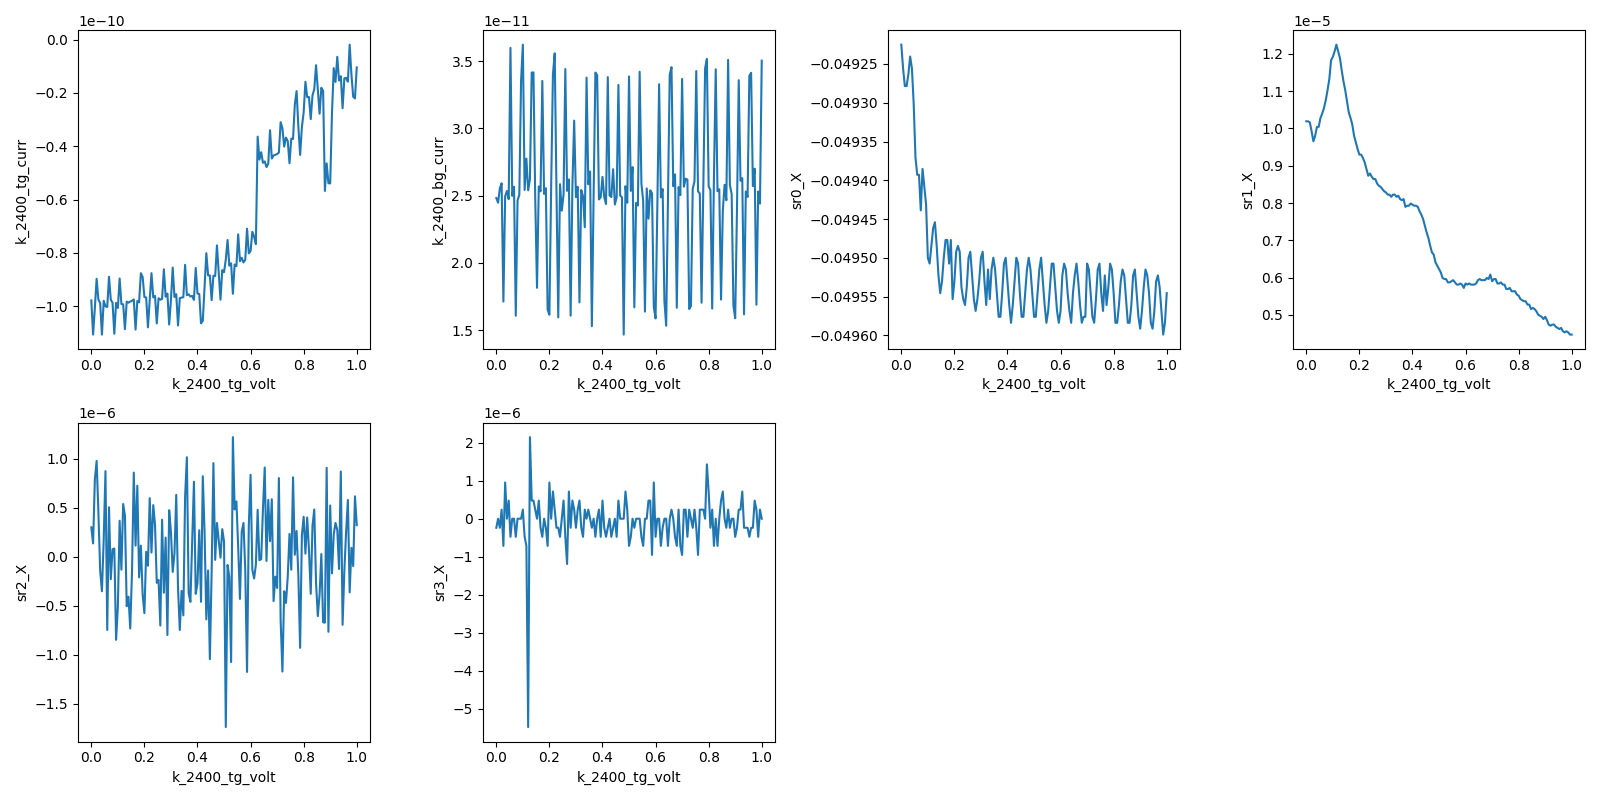

2026-08-24 17:36:48,302 [INFO] Completed in 0h 4m 27s


2026-08-24 17:36:48,303 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\0\data.tsv.gz


2026-08-24 17:36:48,821 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0


    parked k_tg -> +0.0000 V; I_tg=-1.105e-10 A, I_bg=2.459e-11 A

=== leg: k_tg 0 -> -0.3 V (151 pts, delay=0.70 s) ===


2026-08-24 17:36:52,182 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-24 17:36:52,705 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-24 17:36:52,718 [INFO] Starting sweep with ID 1


2026-08-24 17:36:52,719 [INFO] Minimum duration 0h 1m 45s


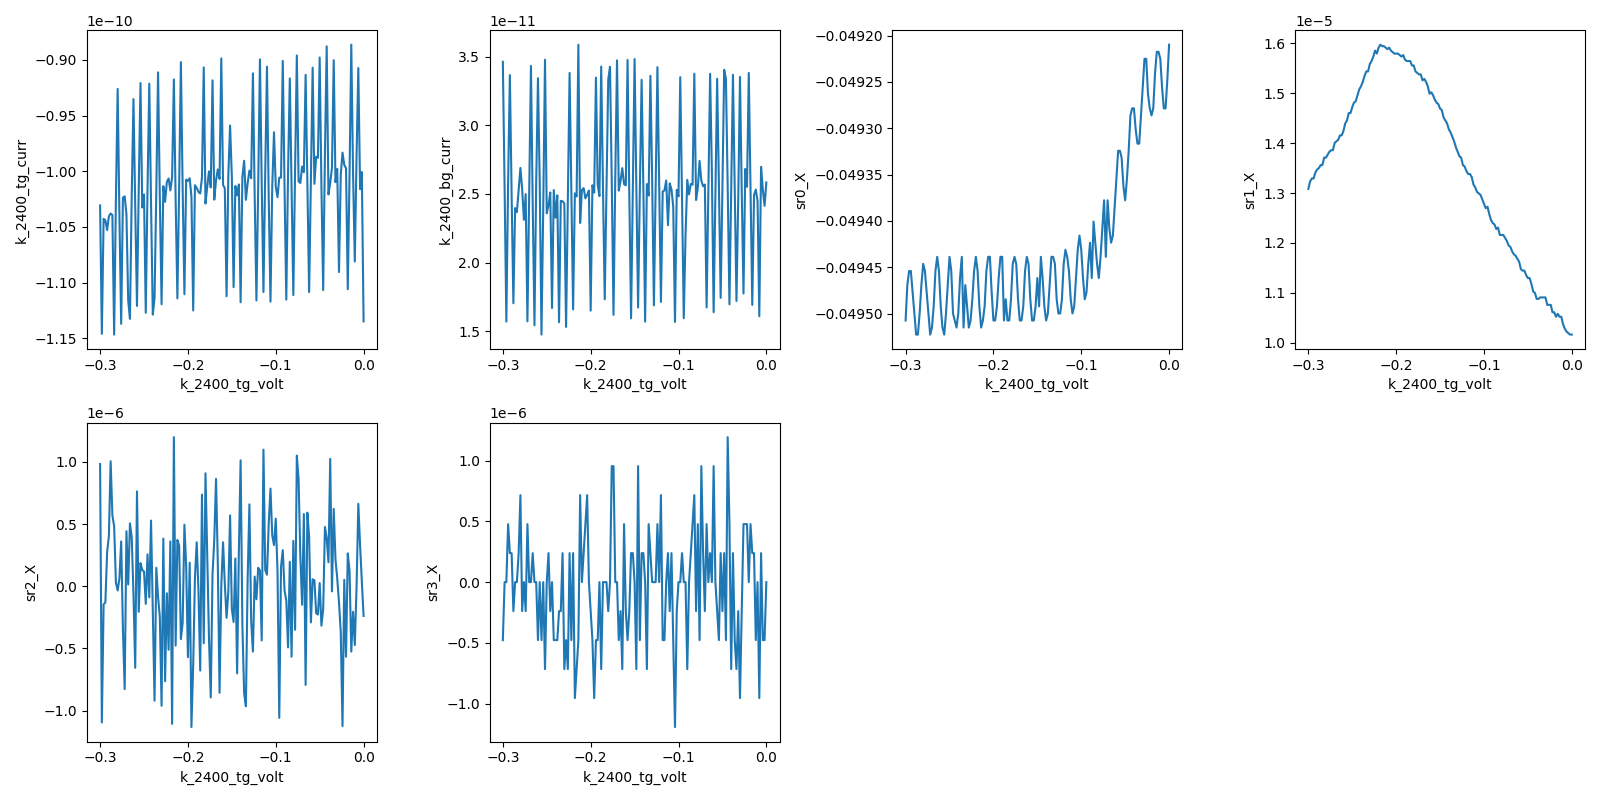

2026-08-24 17:41:18,398 [INFO] Completed in 0h 4m 25s


2026-08-24 17:41:18,398 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\1\data.tsv.gz


2026-08-24 17:41:18,917 [INFO] Ramping k_2400_tg_volt: -0.3 -> 0


    parked k_tg -> +0.0000 V; I_tg=-9.583e-11 A, I_bg=2.423e-11 A

=== leg: k_bg 0 -> +2 V (151 pts, delay=0.70 s) ===


2026-08-24 17:41:21,395 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-24 17:41:21,918 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-24 17:41:21,929 [INFO] Starting sweep with ID 2


2026-08-24 17:41:21,929 [INFO] Minimum duration 0h 1m 45s


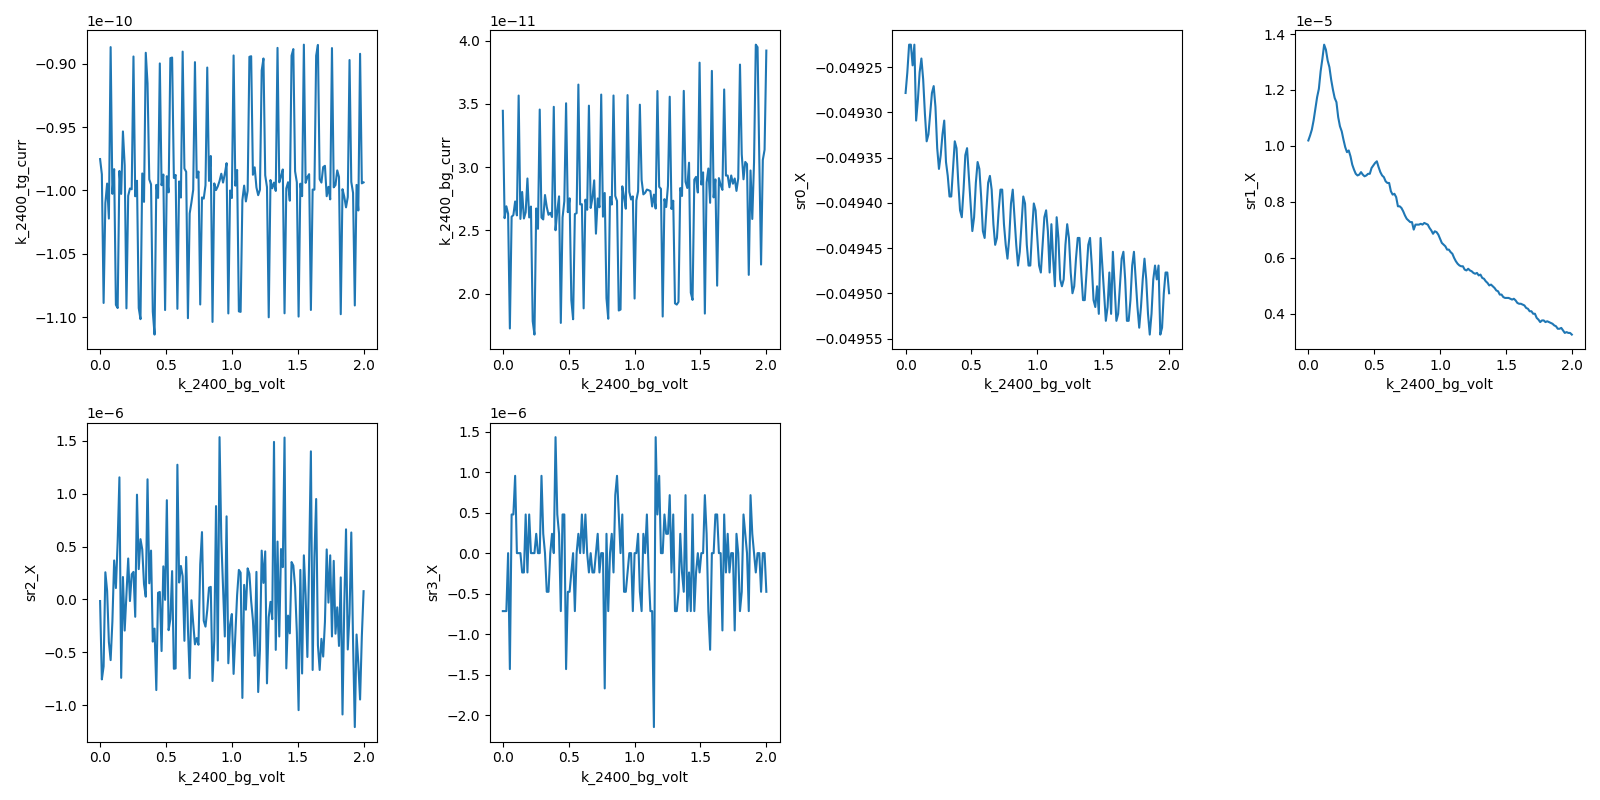

2026-08-24 17:45:50,454 [INFO] Completed in 0h 4m 27s


2026-08-24 17:45:50,454 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\2\data.tsv.gz


2026-08-24 17:45:50,967 [INFO] Ramping k_2400_bg_volt: 2.0 -> 0


    parked k_bg -> +0.0000 V; I_tg=-9.932e-11 A, I_bg=1.879e-11 A

=== leg: k_bg 0 -> -1.3 V (151 pts, delay=0.70 s) ===


2026-08-24 17:45:55,591 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0


2026-08-24 17:45:56,104 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0


2026-08-24 17:45:56,120 [INFO] Starting sweep with ID 3


2026-08-24 17:45:56,121 [INFO] Minimum duration 0h 1m 45s


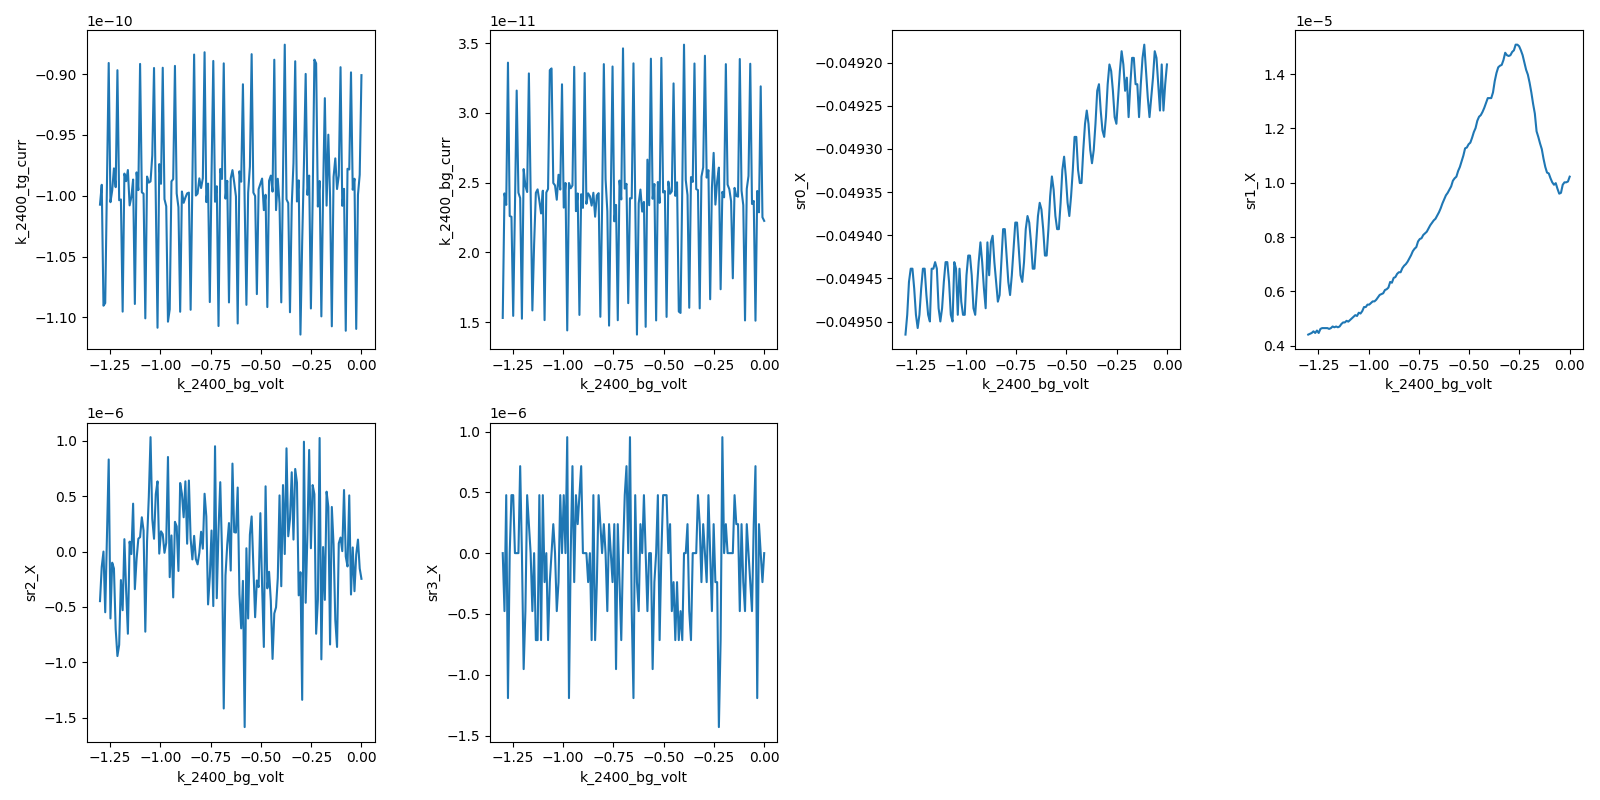

2026-08-24 17:50:23,683 [INFO] Completed in 0h 4m 26s


2026-08-24 17:50:23,684 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\3\data.tsv.gz


2026-08-24 17:50:24,197 [INFO] Ramping k_2400_bg_volt: -1.3 -> 0


    parked k_bg -> +0.0000 V; I_tg=-1.005e-10 A, I_bg=3.750e-11 A

GATE-C: all legs done


final: V_tg=+0.0000 V, V_bg=+0.0000 V, V_si=+0.0000 V


In [22]:
# HERA — Gate C: gate-current sanity check / contact liveness.
# recipe: device-init/gate-current-sanity-check.md (Cell A, all four legs).
# Each leg sweeps one gate 0 -> a committed card limit with the other parked at
# 0, watching both gate currents at pA resolution and every lock-in.
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vtg, _vbg, _vsi = k_2400_tg.volt(), k_2400_bg.volt(), dc205.voltage()
_B, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={_vtg:+.4f} V  V_bg={_vbg:+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vtg) < 1e-3 and abs(_vbg) < 1e-3 and abs(_vsi) < 0.01, "gates not parked at 0"
assert abs(_B) < 0.02, "field not at zero"
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert abs(sr1.filter_slope() - 24) < 1 and abs(sr0.filter_slope() - 24) < 1, "filter slope not 24 dB/oct"
print(f"acquisition: drive={sr1.amplitude()} V @ {sr1.frequency()} Hz, I_bias={I_BIAS:.4e} A, "
      f"tau={sr1.time_constant()} s, dwell={DWELL:.2f} s, "
      f"sr0 sens={sr0.sensitivity():.2e}, sr1 sens={sr1.sensitivity():.2e}")

# --- re-range sr1 for the CNP hunt -------------------------------------
# Committed sens 5e-5 ceilings R_xx at 5e-5/I = ~1 kohm, only 5x the metallic
# 206 ohm. This leg set is the CNP reconnaissance, so head-room matters more
# than resolution in the metallic region: 5e-4 puts the ceiling at ~10 kohm.
# Measure the noise penalty at the new range rather than assuming there is none.
sr1.sensitivity(5e-4)
interruptible_sleep(2.0)
_s = []
for _j in range(16):
    interruptible_sleep(DWELL)
    _s.append(sr1.X())
_s = np.array(_s)
_dR_new = _s.std(ddof=1) / abs(I_BIAS)
print(f"sr1 re-ranged: sens={sr1.sensitivity():.1e} V -> R_xx ceiling "
      f"{sr1.sensitivity()/abs(I_BIAS)/1e3:.1f} kohm; "
      f"load={abs(_s.mean())/sr1.sensitivity():.4f}, "
      f"R_xx={_s.mean()/I_BIAS:.2f} ohm, dR_xx={_dR_new:.3f} ohm "
      f"({_s.std(ddof=1)/abs(_s.mean()):.2%})")
print("  (a railed CNP peak still LOCATES the CNP, which is what Gate C needs;")
print("   precision R_xx at the peak comes later with a range chosen from it)")

N_PTS = 151
LOCKINS = [sr0, sr1, sr2, sr3]
LEGS = [
    (k_tg, "k_tg", TG_MAX), (k_tg, "k_tg", TG_MIN),
    (k_bg, "k_bg", BG_MAX), (k_bg, "k_bg", BG_MIN),
]

meas_config["comments"] = ("Gate C: gate-current sanity check + contact liveness + CNP "
                           "reconnaissance, B=0, V_si=0, base T")
meas_config["Si (V)"] = dc205.voltage()
meas_config["sample_temperature:"] = T_sample()

# pA-floor readback on the gate-current channels; reset in the next cell.
k_tg.nplci(10)
k_bg.nplci(10)
print(f"gate-current nplci -> tg={k_tg.nplci()}, bg={k_bg.nplci()} (pA floor; reset next cell)")

for _gate, _gname, _vend in LEGS:
    _other = k_bg if _gate is k_tg else k_tg
    _oname = "k_bg" if _gate is k_tg else "k_tg"
    print(f"\n=== leg: {_gname} 0 -> {_vend:+g} V ({N_PTS} pts, delay={DWELL:.2f} s) ===")

    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {_gname}')
    s.add_comment(f'leg: 0 -> {_vend:+g} V (committed card limit)')
    s.add_comment(f'{_oname} parked at 0 V; V_si = 0 V; B = 0 T')
    s.add_comment(f'I_bias = {I_BIAS:.4e} A, drive {sr1.amplitude()} V @ {sr1.frequency()} Hz')
    s.add_comment(f'sr1 tau={sr1.time_constant()} s slope={sr1.filter_slope()} dB/oct, dwell={DWELL:.2f} s')
    s.add_comment('Gate C liveness on the provided hardwired configuration: '
                  'source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.')

    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    _xp = _gate.volt
    s.fp(_other.volt)
    s.fp(_gate.curr).fp(_other.curr)
    s.fp(T_sample).fp(T_vaporizer)
    # every live value gets a plot: both gate currents + every lock-in X
    s.plot(_xp, k_tg.curr)
    s.plot(_xp, k_bg.curr)
    for _lia in LOCKINS:
        s.fp(_lia.X).fp(_lia.P)
        s.plot(_xp, _lia.X)

    try:
        s.sweep(_gate.volt, np.linspace(0, _vend, N_PTS), delay=DWELL)
    finally:
        s.ramp(_gate.volt, 0)
        print(f"    parked {_gname} -> {_gate.volt():+.4f} V; "
              f"I_tg={k_tg.curr():.3e} A, I_bg={k_bg.curr():.3e} A")

print("\nGATE-C: all legs done")
print(f"final: V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V, V_si={dc205.voltage():+.4f} V")


## HERA — gate-current-sanity-check Cell B: reset nplci

All four Gate C legs completed clean — no gross turn-up off the charging slope on
either gate, no cross-gate tracking, both lock-ins live the whole way, and
`sr1` never above 3% of full scale. The recipe's condition for running Cell B is
met.

Resetting the gate-current `nplci` from 10 back to 1: the pA floor existed for the
leakage check, and at ~0.30 s/pt of extra readback it would add ~19 minutes to the
gate map. Validators are re-printed as a check that nothing has moved them.

One caveat carried forward rather than resolved: the TG leakage onset at
V_tg ≈ 0.62 V (+88 pA excess at +1.0 V, run 0). At `nplci = 1` the gate-current
readback coarsens, but 88 pA stays comfortably resolvable — the map will still
show it if it grows.


In [23]:
# HERA — gate-current-sanity-check Cell B: reset gate-current nplci.
# Validators were committed in SAFETIES (cell 18) — nothing to re-commit here.
# Run only after every leg looked safe.
k_tg.nplci(1)
k_bg.nplci(1)
print(f"nplci reset: k_tg={k_tg.nplci()}, k_bg={k_bg.nplci()}")
print("k_tg.volt validator:", k_tg.volt.vals)
print("k_bg.volt validator:", k_bg.volt.vals)
print("dc205.smart_voltage validator:", dc205.smart_voltage.vals)
print("magnet.field validator:", magnet.field.vals)
print(f"gates: V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V, V_si={dc205.voltage():+.4f} V")
print(f"currents: I_tg={k_tg.curr():.3e} A, I_bg={k_bg.curr():.3e} A")
print(f"B={magnet.field():+.4f} T, T_sample={T_sample():.3f} K")


nplci reset: k_tg=1.0, k_bg=1.0
k_tg.volt validator: <Numbers -0.3<=v<=1.0>
k_bg.volt validator: <Numbers -1.3<=v<=2.0>
dc205.smart_voltage validator: <Numbers -25.0<=v<=25.0>
magnet.field validator: <Numbers -10.0<=v<=10.0>
gates: V_tg=+0.0000 V, V_bg=+0.0000 V, V_si=+0.0000 V


currents: I_tg=-9.767e-11 A, I_bg=2.753e-11 A
B=+0.0063 T, T_sample=1.175 K


## HERA — first 0 T gate map (the load-bearing measurement)

> **17:53** · First 0 T gate map: V\_tg fast [-0.3,+1.0]x101 (13 mV), V\_bg slow [-1.3,+1.3]x37 (72 mV), 3737 pts, fast\_delay=0.70 s, slow\_delay=1.0 s, I\_bias=49.2 nA, B=0, V\_si=0, sr1 sens 5e-4; substrate for cnp-and-dline-calibration · **ETA ~19:38** (≈1h45m)

`recipe: measurements/gatemap.md`. Preceded by `gate-current-sanity-check` Cell B
(nplci reset) in the cell above.

**What Gate C established** (runs 0–3, four legs, 151/151 each, none interrupted,
T flat at 1.175 K): gates safe on both polarities, the provided hardwired
configuration fully live (sr0 and sr1 clean and resistive, sr2/sr3 at the n.c.
floor), and `sr1` never above 3% of full scale. And **two resistance ridges, not
one**, along each gate axis:

| ridge | V_tg at V_bg = 0 | V_bg at V_tg = 0 | implied c_bg/c_tg |
|---|---|---|---|
| A | −0.2152 V (322 Ω) | −0.2642 V (303 Ω) | 0.814 |
| B | +0.1121 V (242 Ω) | +0.1284 V (265 Ω) | 0.873 |

geometry prior: 0.864.

Both ridges return a ratio consistent with the prior and with each other to
within ~6–7%, which says they are **parallel** — two CNP lines, i.e. two regions
of differing intrinsic doping in series along the B_1−B_2 span, separated by
roughly 0.6×10¹² cm⁻². (My first pass at this, from raw argmax, gave 0.830 and
0.958 and I read it as *non*-parallel; smoothing plus parabolic refinement moved
ridge B from 0.958 to 0.873 and reversed the conclusion. The two-point estimate
is too sensitive to peak-picking to carry a claim — which is the argument for
this map.)

**Why that matters more than it looks.** If B_1−B_2 spans two domains at
different densities, then at any gate setting the two regions carry different n,
and each contributes its own SdH frequency. **Two tones from two doping domains
would masquerade as two Fermi surfaces** — precisely the ABAB signature the
investigation is looking for. This is a confound that has to be resolved before
any FS count means anything, and it is not the stacking-domain case the
investigation discusses (that one shares a common gated density); here the
densities themselves differ.

**What this map decides**, and why it is worth 1.6 h of zero-field time before
any magnet time:

1. **Both ridges' slopes, properly fitted** — per-row argmax with continuity
   enforcement, robust line fit, residuals reported (`cnp-and-dline-calibration`
   Step 1–2). Parallel to within residuals ⇒ two doping domains. Non-parallel ⇒
   band structure, and one of the two is not a CNP. A ridge at *constant V_bg*
   (infinite slope) would instead mean a region the top gate does not cover.
2. **The data-calibrated c_bg/c_tg**, replacing the geometry prior — ratio
   data-grade, absolute scale still prior-grade until a quantum-Hall lever arm
   lands (Step 5 upgrade path).
3. **Each ridge's resistance at D = 0.** The Gate C peak heights are all at
   finite D — ridge A sits at ~2× ridge B's |D| and reads higher, and both read
   higher at D < 0 than D > 0, so the height difference may be pure |D| effect.
   A tetralayer CNP that is semimetallic rather than insulating is weak evidence
   about stacking, but only if read at D ≈ 0, and only as consistent-with
   (survey §5: three candidate parents for an insulating CNP).

**Grid and the coverage trade.** V_tg fast, [−0.3, +1.0] × 101 (13 mV);
V_bg slow, [−1.3, +1.3] × 37 (72 mV); 3737 points. The full committed TG window
is used because the ridges sweep across all of it (ridge A reaches V_tg ≈ +1.03
at V_bg = −1.3) and because the D = 0 line needs V_tg = 1.0 to reach n ≈
+3.3×10¹² cm⁻², where the ABAB and ABCA templates separate. **Excluded:
V_bg ∈ (1.3, 2.0]** — Gate C run 2 shows R falling smoothly there with no new
ridge, and it is high-D electron side, off the D ≈ 0 operating point. Adding it
back is ~10 rows ≈ 25 min if the map argues for it.

**Top-gate leakage, stated on the page.** Gate C run 0 shows I_tg flat at −97 pA
to V_tg ≈ 0.62 V, then a sharp turn-on reaching −10 pA at +1.0 V: **+88 pA of
voltage-dependent gate current with an onset at 0.62 V**, TG-positive only. Below
the recipe's 1 nA abort and just under its 100 pA surface-it line. I am running
to the committed +1.0 V because capping at 0.6 V would drop the reachable
electron density from 3.3 to 1.9×10¹² — below where the templates separate, i.e.
it would cost the campaign its answer. The operating limit is the operator's;
Zack has been pinged with the number and can cap it. `hera-watch` warns at ≥100 pA
excess sustained, and the fast axis crosses the onset every row so any growth
shows immediately.

**Pricing, from measured overhead.** Gate C ran 1.79 s/pt at `nplci = 10`
(33.5 rows/min, calibrating run 0). Dropping the gate-current NPLC to 1 removes
~0.30 s/pt → ~1.49 s/pt: 3737 pts ≈ 1.55 h, plus 37 row-flybacks
(1.3 V / 5 mV × 6 ms + 1 s slow_delay ≈ 2.6 s) ≈ 1.6 min. **ETA 1h45m** with the
5–10% over-run margin this rig's session evidence warrants.

**Checkpoints.** First rows — leakage, railing, dead channel, and a re-price of
s/pt against the 1.49 estimate; then periodically as rows land, with the CNP
ridge trackable from the first few rows onward.


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0063 T  T_sample=1.175 K
acquisition: drive=5.0 V, I_bias=4.9233e-08 A, tau=0.1 s, dwell=0.70 s, sr0 sens=2.00e-01, sr1 sens=5.00e-04 (R ceiling 10.2 kohm)
grid: V_tg -0.300 -> +1.000 V x101 (13.0 mV)  [fast]
      V_bg -1.300 -> +1.300 V x37 (72.2 mV)  [slow]
      3737 points
2026-08-24 17:53:51,709 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.3


2026-08-24 17:53:53,426 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.3


2026-08-24 17:54:03,812 [INFO] Starting megasweep with ID 4


2026-08-24 17:54:03,813 [INFO] Minimum duration 0h 44m 12s


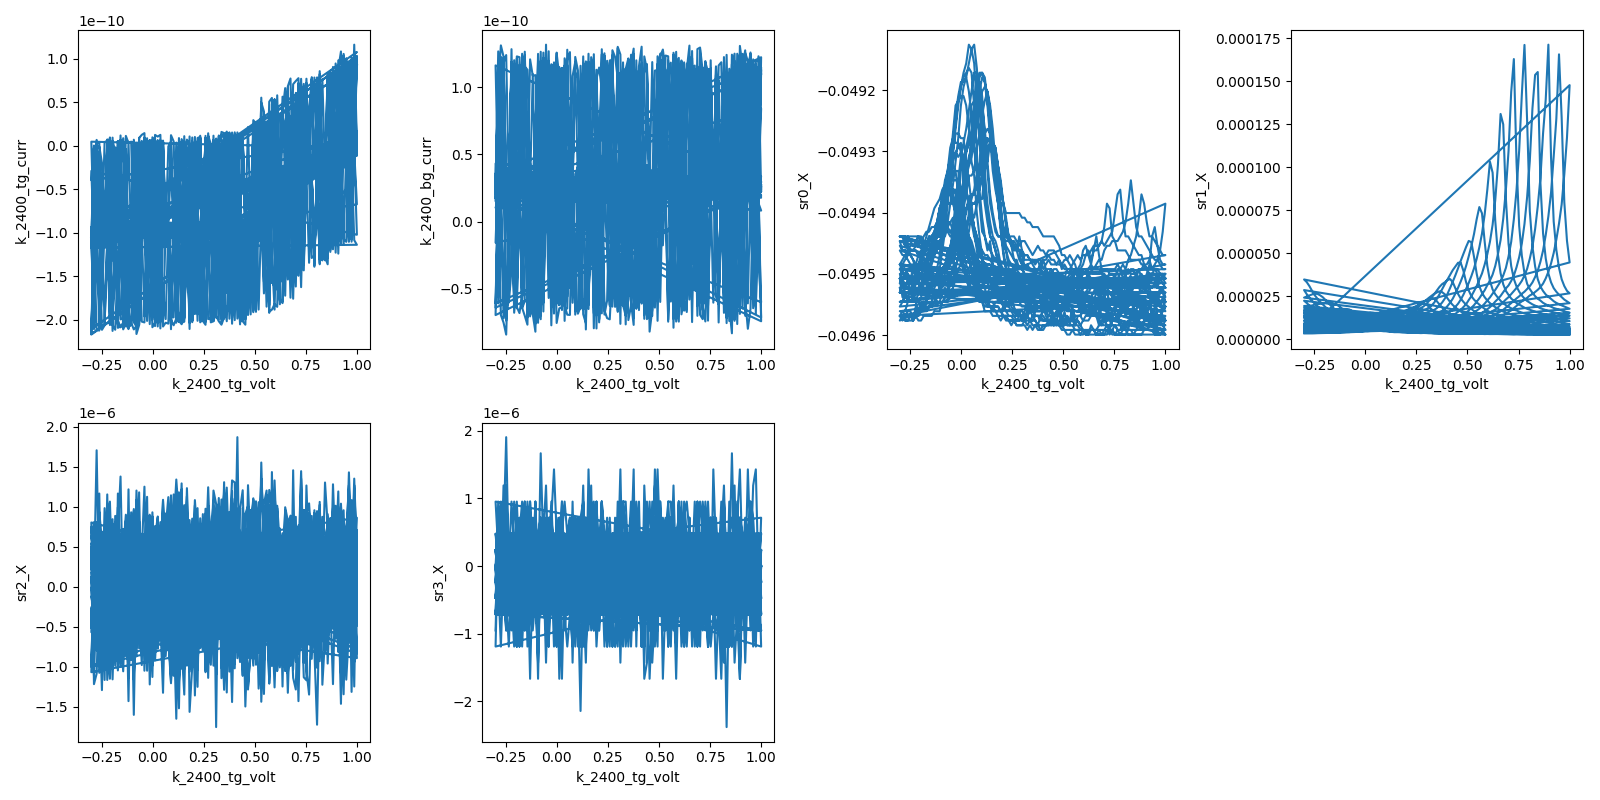

2026-08-24 18:46:14,777 [INFO] Completed in 0h 52m 10s


2026-08-24 18:46:14,777 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\4\data.tsv.gz


2026-08-24 18:46:14,837 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0


2026-08-24 18:46:16,151 [INFO] Ramping k_2400_bg_volt: 1.3 -> 0


parked: V_tg=+0.0000 V, V_bg=+0.0000 V; I_tg=-1.097e-10 A, I_bg=1.119e-11 A
GATEMAP: done


In [24]:
# HERA — first 0 T gate map. recipe: measurements/gatemap.md
# Axis-aligned megasweep over (V_tg fast, V_bg slow) at B = 0, V_si = 0.
# Sweeping raw gate volts (not (n, D)) because the cap ratio is not yet
# data-calibrated — that is what this map exists to produce.
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vsi = dc205.voltage()
_B, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={k_tg.volt():+.4f} V  V_bg={k_bg.volt():+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vsi) < 0.01, "V_si not at 0"
assert abs(_B) < 0.02, "field not at zero"
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not reset to 1 (Cell B)"
assert abs(sr1.filter_slope() - 24) < 1, "sr1 filter slope not 24 dB/oct"
assert np.isclose(sr1.time_constant(), 0.1), "sr1 tau not the committed 0.1 s"
print(f"acquisition: drive={sr1.amplitude()} V, I_bias={I_BIAS:.4e} A, tau={sr1.time_constant()} s, "
      f"dwell={DWELL:.2f} s, sr0 sens={sr0.sensitivity():.2e}, sr1 sens={sr1.sensitivity():.2e} "
      f"(R ceiling {sr1.sensitivity()/abs(I_BIAS)/1e3:.1f} kohm)")

TG_V = np.linspace(TG_MIN, TG_MAX, 101)     # fast axis, 13 mV steps
BG_V = np.linspace(-1.3, 1.3, 37)           # slow axis, 72 mV rows
assert TG_V.min() >= TG_MIN and TG_V.max() <= TG_MAX, "TG vector outside committed validator"
assert BG_V.min() >= BG_MIN and BG_V.max() <= BG_MAX, "BG vector outside committed validator"
print(f"grid: V_tg {TG_V[0]:+.3f} -> {TG_V[-1]:+.3f} V x{len(TG_V)} ({np.diff(TG_V)[0]*1e3:.1f} mV)  "
      f"[fast]")
print(f"      V_bg {BG_V[0]:+.3f} -> {BG_V[-1]:+.3f} V x{len(BG_V)} ({np.diff(BG_V)[0]*1e3:.1f} mV)  "
      f"[slow]")
print(f"      {len(TG_V)*len(BG_V)} points")

meas_config["comments"] = ("first 0 T gate map, full committed TG window x BG [-1.3,+1.3]; "
                           "CNP-line + (n,D) calibration substrate")
meas_config["Si (V)"] = dc205.voltage()
meas_config["sample_temperature:"] = T_sample()

s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('first 0 T gate map, B = 0 T, V_si = 0 V, base T')
s.add_comment(f'V_tg fast {TG_V[0]:+g}..{TG_V[-1]:+g} V x{len(TG_V)}; '
              f'V_bg slow {BG_V[0]:+g}..{BG_V[-1]:+g} V x{len(BG_V)}')
s.add_comment(f'I_bias = {I_BIAS:.4e} A, drive {sr1.amplitude()} V @ {sr1.frequency()} Hz')
s.add_comment(f'sr1 tau={sr1.time_constant()} s slope={sr1.filter_slope()} dB/oct, '
              f'fast_delay={DWELL:.2f} s (measured 7*tau settling floor)')
s.add_comment('substrate for device-init/cnp-and-dline-calibration')
s.add_comment('contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.')
s.add_comment('NOTE: TG leakage onset at V_tg ~0.62 V, reaching +88 pA excess at +1.0 V '
              '(Gate C run 0) - below the 1 nA abort; watch k_2400_tg_curr')

s.ramp(k_bg.volt, BG_V[0])
s.ramp(k_tg.volt, TG_V[0])
interruptible_sleep(10)

s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample).fp(T_vaporizer)
# every live value gets a plot
s.plot(k_tg.volt, k_tg.curr)
s.plot(k_tg.volt, k_bg.curr)
for _lia in (sr0, sr1, sr2, sr3):
    s.fp(_lia.X).fp(_lia.P)
    s.plot(k_tg.volt, _lia.X)

try:
    s.megasweep(k_bg.volt, BG_V, k_tg.volt, TG_V, slow_delay=1.0, fast_delay=DWELL)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
    print(f"parked: V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V; "
          f"I_tg={k_tg.curr():.3e} A, I_bg={k_bg.curr():.3e} A")

print("GATEMAP: done")


## HERA — calibration Landau fan at V_bg = 0 (first field of the session)

> **18:54** · Calibration Landau fan: B slow 0->6.0 T x13 (0.5 T), V\_tg fast [-0.3,+1.0]x201 (6.5 mV) at V\_bg=0, fast\_delay=0.70 s, slow\_delay=2.0 s, I\_bias=49.2 nA, sr1 sens 5e-4; absolute lever arm from LL spacing + CNP identification + one-fan-or-two domain test · **ETA ~20:34** (≈1h40m)

`recipe: measurements/landau-fan-vti.md`. **This is a calibration fan, not the
investigation's Step-4 FS-count fan** — its B rows are deliberately far too
coarse for a 1/B FFT. It is here because the zero-field calibration did not
close, and going into field is the way to close it.

**What the gate map (run 4) settled and what it did not.** Settled: the device
has **two resistance features**, and they are not two co-existing doping domains
in the naive sense — ridge B is strong at large +D and dies toward D = 0, while
ridge A is absent below V_bg = −0.29 and strengthens toward large −D (a
second-derivative scan finds no trace of ridge A in any of the 14 rows from
V_bg = −1.30 to −0.36). Also settled: R_xx at the ridge runs from ~2.4 kΩ at
|D| ≈ 0.26 V/nm down to ~230 Ω near D ≈ 0, i.e. the feature gaps strongly with
displacement field.

Not settled — and this is the problem: **ridge B is not a constant-density
contour.** n is linear in both gate voltages, so every constant-n locus is a
straight line in gate space; ridge B's slope changes monotonically from −0.767
to −0.594 across its own track, and a quadratic term cuts the fit residual from
18.1 mV to 3.1 mV. Neither ridge's operating-window slope (−0.576 for B, −0.673
for A) matches the geometry prior of −0.864. So I cannot presently say which
feature is the charge-neutrality point, and every (n, D) coordinate the
FS-count method would quote depends on that answer.

**Why field settles it, and nothing at zero field will.** At fixed B, adjacent
Landau-level minima are separated by **Δn = eB/h** — exactly, from degeneracy
alone, with no band model and no assumed capacitance. Measuring their spacing in
gate voltage therefore gives the lever arm *absolutely*:
c_tg = e²B / (h · ΔV_tg). That is precisely the quantum-Hall lever-arm upgrade
`cnp-and-dline-calibration` Step 5 holds open as the way to promote the scale
from geometry-prior to data-grade, and it simultaneously answers the two things
zero field left ambiguous:

1. **Which feature is the CNP** — the CNP is the ν = 0 state, the one the LL
   fan radiates *from*. A feature that is not a charge-neutrality point does not
   emit a Landau fan.
2. **One region or two** — two domains at different densities would produce
   **two superposed fans with different origins**, which is unmistakable. This
   is the direct test of the confound Gate C raised, and the reason it matters
   is unchanged: two SdH tones from two doping domains would masquerade as the
   two Fermi surfaces that are exactly the ABAB signature this campaign is
   trying to detect.

**Design.** V_bg = 0 is chosen because **both ridges sit inside the top-gate
window there** (B at V_tg = +0.113, A at −0.203), so a single fast sweep crosses
both and any second fan origin is caught in the same rows. B slow over
0 → 6 T in 0.5 T steps (13 rows); V_tg fast over the full committed window in
201 points (6.5 mV). At 6 T one filling factor spans ΔV_tg ≈ 83 mV ≈ 13 fast-axis
points on the geometry prior — comfortably resolvable, and the *measured*
spacing is the output, so a wrong prior only changes how many points I get, not
the answer.

**Cost, and why the fan shape is affordable.** B is the **slow** axis, so the
magnet ramps once per row rather than once per point — the VTI variant's key
cost fact, and the reason a fan is cheap here while a fine 1D field sweep is
not (a blocking per-point settle would dominate). Traverse 6 T / 0.137 T·min⁻¹
≈ 44 min, grid 13 × 201 × 0.87 s ≈ 38 min. **ETA 1h40m** with margin.

**Coverage trade, stated.** V_bg is pinned at 0, so D varies along the fast axis
(−0.047 to +0.157 V/nm) rather than being held. That is acceptable *for this
purpose* — the LL spacing that sets the lever arm is a degeneracy statement and
does not care about D — but it means this fan does **not** deliver the
investigation's D ≈ 0 requirement and must not be read as an FS-count fan. A
second short fan with V_tg fixed and V_bg fast would give c_bg the same way; I
expect to need it, and it is cheap once the magnet is already at field.

**`sr1` stays at 500 µV** (≈10 kΩ ceiling). The CNP may well rail at high field
where the ν = 0 state gets strongly insulating — that is an accepted trade,
because the lever arm is read from LL minima on the *metallic flanks*, where a
tighter range keeps resolution. `hera-watch` reports the load per row, so railing
will be visible rather than silent.

**Field endpoint:** the sweep ends at 6 T and I leave it there — never
re-traverse without a reason (rig card). The next step decides where the magnet
goes, and riding it home as a measured ramp is the natural SdH spot check.

**Checkpoints:** first rows for railing/leakage and a per-point re-price; then
per-row as the fan builds, with LL structure expected to emerge above ~2 T.


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+0.0063 T  T_sample=1.173 K
grid: B 0.00 -> 6.00 T x13 rows (0.50 T)  [slow]
      V_tg -0.300 -> +1.000 V x201 (6.5 mV) at V_bg = +0.00 V  [fast]
      2613 points; traverse 44 min + grid 38 min
      at 6 T: dn per filling factor = 0.145e12 cm^-2 -> dV_tg = 83 mV = 12.8 fast-axis points
2026-08-24 18:54:23,446 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0.0


2026-08-24 18:54:23,514 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.3


positioned: V_tg=-0.3000, V_bg=+0.0000, B=+0.0064 T
2026-08-24 18:54:34,032 [INFO] Starting megasweep with ID 5


2026-08-24 18:54:34,033 [INFO] Minimum duration 0h 30m 55s


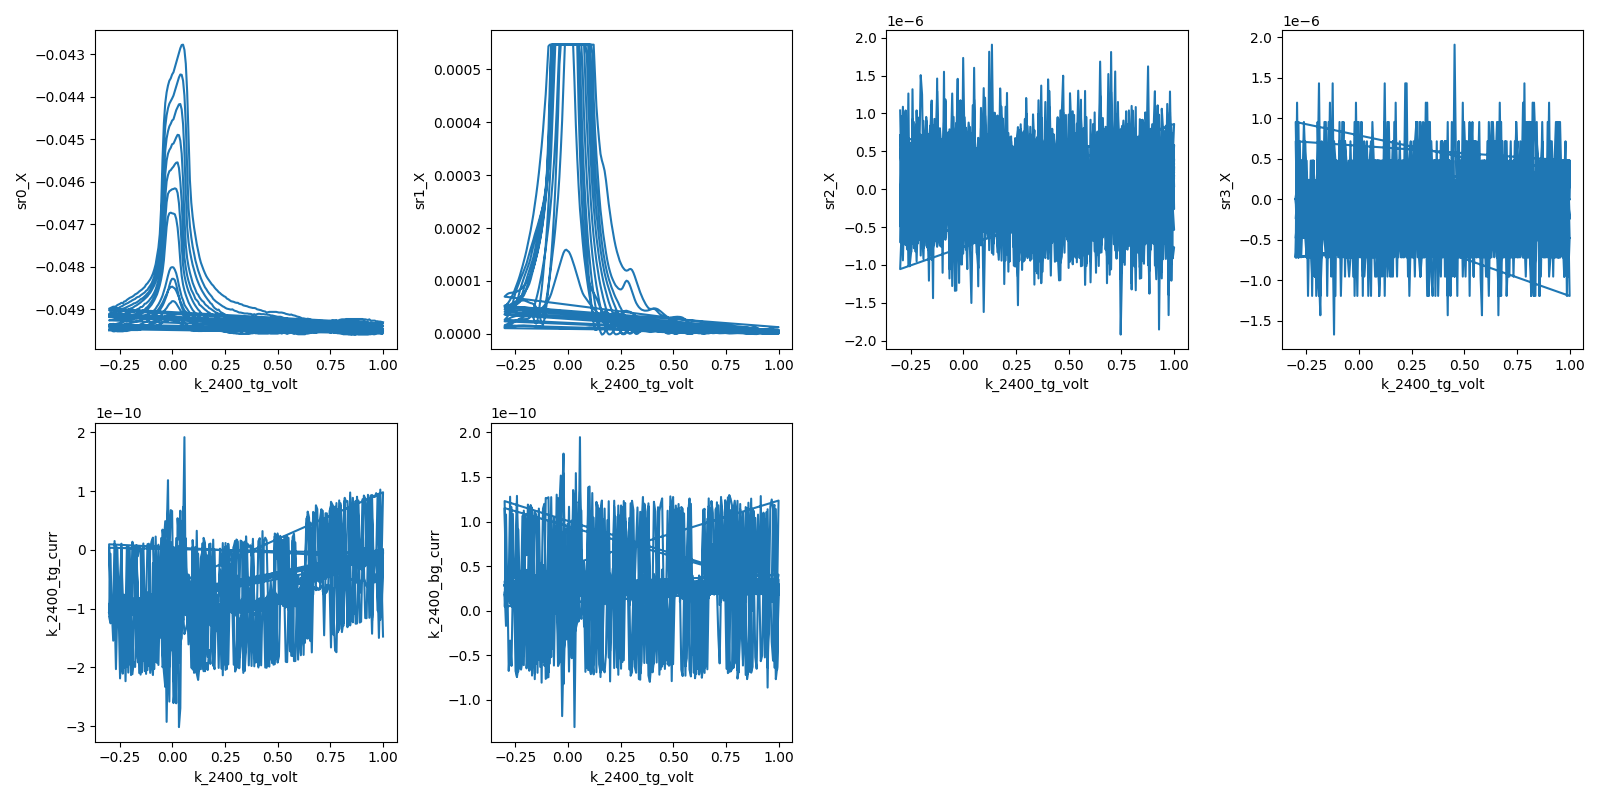

2026-08-24 20:14:48,225 [INFO] Completed in 1h 20m 13s


2026-08-24 20:14:48,226 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\5\data.tsv.gz


sweep exited at B=+6.0063 T, V_tg=+1.0000 V
2026-08-24 20:14:48,358 [INFO] Ramping k_2400_tg_volt: 1.0 -> 0


parked V_tg -> +0.0000 V (field left where the sweep ended, by design -- next step decides the endpoint)

CALFAN: done.  B=+6.0063 T, V_tg=+0.0000 V, V_bg=+0.0000 V, T=1.261 K


In [25]:
# HERA — calibration Landau fan. recipe: measurements/landau-fan-vti.md
# B slow (magnet ramps once per row), V_tg fast at fixed V_bg = 0.
# Purpose: absolute lever arm from LL spacing + unambiguous CNP location +
# the one-fan-or-two test. NOT the FS-count fan (B rows are far too coarse
# for a 1/B FFT -- see the markdown).
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vsi = dc205.voltage()
_B0, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={k_tg.volt():+.4f} V  V_bg={k_bg.volt():+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B0:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vsi) < 0.01, "V_si not at 0"
assert abs(_B0) < 0.05, "field not near zero -- fan assumes it starts at 0 T"
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not 1"
assert np.isclose(sr1.time_constant(), 0.1) and abs(sr1.filter_slope() - 24) < 1, \
    "sr1 not at the committed tau/slope"
assert magnet.persistent_switch_on() and magnet.output_enabled(), "magnet not ready"

B_MAX = 6.0
B_V = np.arange(0.0, B_MAX + 1e-9, 0.5)          # 13 rows, magnet ramps per row
TG_V = np.linspace(TG_MIN, TG_MAX, 201)          # 6.5 mV steps
V_BG_FIXED = 0.0

assert B_V.max() <= B_SESSION_CAP, "B vector exceeds the committed session cap"
assert TG_V.min() >= TG_MIN and TG_V.max() <= TG_MAX, "TG vector outside validator"
assert BG_MIN <= V_BG_FIXED <= BG_MAX, "V_bg outside validator"

print(f"grid: B {B_V[0]:.2f} -> {B_V[-1]:.2f} T x{len(B_V)} rows ({np.diff(B_V)[0]:.2f} T)  [slow]")
print(f"      V_tg {TG_V[0]:+.3f} -> {TG_V[-1]:+.3f} V x{len(TG_V)} "
      f"({np.diff(TG_V)[0]*1e3:.1f} mV) at V_bg = {V_BG_FIXED:+.2f} V  [fast]")
print(f"      {len(B_V)*len(TG_V)} points; traverse {B_MAX/0.137:.0f} min + "
      f"grid {len(B_V)*len(TG_V)*0.87/60:.0f} min")
# Landau-level spacing in V_tg at the top field, on the geometry prior --
# this is what has to be resolvable for the lever-arm read.
_dn_per_nu = cst.e * B_MAX / cst.h * 1e-4        # cm^-2 per filling factor
_dvtg = _dn_per_nu / (2.7960593112e-3 / cst.e * 1e-4)
print(f"      at {B_MAX:.0f} T: dn per filling factor = {_dn_per_nu*1e-12:.3f}e12 cm^-2 "
      f"-> dV_tg = {_dvtg*1e3:.0f} mV = {_dvtg/np.diff(TG_V)[0]:.1f} fast-axis points")

meas_config["comments"] = ("calibration Landau fan at V_bg = 0: absolute lever arm from LL "
                           "spacing, CNP location, and the one-fan-or-two domain test")
meas_config["Si (V)"] = dc205.voltage()
meas_config["sample_temperature:"] = T_sample()

s = sweep.AsyncStation(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment('CALIBRATION fan (lever arm + CNP identification), not the FS-count fan')
s.add_comment(f'B slow {B_V[0]:g}..{B_V[-1]:g} T x{len(B_V)}; '
              f'V_tg fast {TG_V[0]:+g}..{TG_V[-1]:+g} V x{len(TG_V)} at V_bg = {V_BG_FIXED:+g} V')
s.add_comment('B rows 0.5 T are deliberately coarse: this fan is read as LL structure vs gate '
              'at each field, NOT by 1/B FFT (that needs the sdh-spot-check grid)')
s.add_comment(f'I_bias = {I_BIAS:.4e} A, drive {sr1.amplitude()} V @ {sr1.frequency()} Hz')
s.add_comment(f'sr1 tau={sr1.time_constant()} s slope={sr1.filter_slope()} dB/oct, '
              f'fast_delay={DWELL:.2f} s; sr1 sens {sr1.sensitivity():.1e} '
              f'(R ceiling ~{sr1.sensitivity()/abs(I_BIAS)/1e3:.0f} kohm, CNP may rail at high B)')
s.add_comment('crosses BOTH gate-map ridges: B at V_tg=+0.113, A at V_tg=-0.203 (run 4)')
s.add_comment('contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.')

s.ramp(k_bg.volt, V_BG_FIXED)
s.ramp(k_tg.volt, TG_V[0])
interruptible_sleep(10)
print(f"positioned: V_tg={k_tg.volt():+.4f}, V_bg={k_bg.volt():+.4f}, B={magnet.field():+.4f} T")

s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample).fp(T_vaporizer)
for _lia in (sr0, sr1, sr2, sr3):
    s.fp(_lia.X).fp(_lia.P)
    s.plot(k_tg.volt, _lia.X)
s.plot(k_tg.volt, k_tg.curr)
s.plot(k_tg.volt, k_bg.curr)

try:
    s.megasweep(magnet.field, B_V, k_tg.volt, TG_V, slow_delay=2.0, fast_delay=DWELL)
finally:
    print(f"sweep exited at B={magnet.field():+.4f} T, V_tg={k_tg.volt():+.4f} V")
    s.ramp(k_tg.volt, 0)
    print(f"parked V_tg -> {k_tg.volt():+.4f} V (field left where the sweep ended, "
          f"by design -- next step decides the endpoint)")

print(f"\nCALFAN: done.  B={magnet.field():+.4f} T, V_tg={k_tg.volt():+.4f} V, "
      f"V_bg={k_bg.volt():+.4f} V, T={T_sample():.3f} K")


## HERA — back-gate calibration fan, measured on the descent from 6 T

> **20:17** · Back-gate calibration fan on the descent: B slow 6->1 T x6 (descending), V\_bg fast [-1.3,+2.0]x301 (11 mV) at V\_tg=+0.0216 (measured CNP), fast\_delay=0.70 s; absolute c\_bg from LL spacing + second CNP-line point + both carrier signs · **ETA ~21:32** (≈1h15m)

`recipe: measurements/landau-fan-vti.md`. Second calibration fan; run 5 gave the
top gate, this gives the back gate, and it does so **on the way home** rather
than as a separate traverse.

**What run 5 settled.** The Landau rays converge on a single point:
seven tracked rays, six of the seven B = 0 intercepts inside ±9 mV, giving
**CNP at V_tg = +0.021 ± 0.007 V** (at V_bg = 0). Their slopes fall in near-exact
ratio **4 : 8 : 12 : 16 : 20 : 24** with slope/ν consistent to **1.4%** across all
seven, giving **α = 0.01540 V/(T·ν)** and hence, from degeneracy alone,
**c_tg = 2.515×10⁻³ F/m², dn/dV_tg = 1.570×10¹² cm⁻²/V** — 0.90× the geometry
prior, implying a top-gate hBN of 10.6 nm against the card's 9.5 nm. This is the
`cnp-and-dline-calibration` Step-5 lever-arm upgrade: the top-gate scale is now
**data-grade, not prior-grade**.

Three things follow, and the third is why this cell exists.

1. **One CNP, not two.** A single convergence point retires the two-doping-domain
   hypothesis, and with it the confound that two domains' SdH tones would
   masquerade as the ABAB two-Fermi-surface signature. That was the question the
   fan was launched to answer.
2. **Neither zero-field ridge is the CNP.** Ridge A (−0.203) and ridge B (+0.113)
   flank the true CNP at +0.021 — which is the shallow R_xx *minimum* visible in
   the very first Gate C leg. R_xx is locally minimal at charge neutrality with
   maxima on either side. That explains everything that failed at zero field: the
   ridge slopes never matched the geometry prior and ridge B was measurably
   curved because **they were never constant-density loci**. A semimetal with
   overlapping electron and hole bands has exactly this shape, and ABAB
   tetralayer is predicted to be one — but the investigation is explicit that CNP
   character is not a stacking read (survey §5 gives three candidate parents), so
   this is an observation to test, not evidence to bank.
3. **The top gate alone cannot reach the design density.** With the measured
   lever arm, the V_bg = 0 cut spans only **n ∈ [−0.50, +1.54]×10¹² cm⁻²**. The
   investigation needs |n| ≳ 2–3×10¹² for the ABAB and ABCA templates to
   separate — at +1×10¹² ABAB genuinely mimics an ABCA singleton within the scale
   prior. **The campaign therefore depends on the back gate**, and c_bg is still
   unmeasured.

**This measurement.** Same method, other gate: V_bg fast at fixed V_tg, B slow.
Fixing V_tg at the measured CNP (+0.0216 V) puts charge neutrality at V_bg = 0,
centring the fast axis on it, and the full committed back-gate window then
reaches **both carrier signs** — roughly n ∈ [−1.8, +2.7]×10¹² on the geometry
ratio, far better coverage than the top-gate cut and the first look at the hole
side the investigation wants spot-checked. Output: c_bg absolutely from LL
spacing, plus a second point on the CNP line, which with run 5's point fixes the
line's slope — the ratio that the zero-field map could not deliver.

**B descends 6 → 1 T in six rows.** The rig card's rule is never to re-traverse
without a reason; the magnet has to come down anyway, so the descent is measured
instead of wasted (the base recipe's "plan the direction so the fan ends where
the next measurement needs it"). Six field rows also give long lever arms for ray
fitting, and ending at 1 T leaves a short ramp to zero for close-out.

**Sampling.** 301 points over the 3.3 V window (11 mV). Predicted LL spacing at
6 T is ≈0.43 V per Δν = 4 on the geometry ratio, so ~8 periods across the window
at ~39 points per period — comfortable, and the *measured* spacing is the output
so a wrong prediction costs resolution, not correctness.

**Cost:** descent 5 T / 0.137 T·min⁻¹ ≈ 37 min, grid 6 × 301 × 0.87 s ≈ 26 min.
**ETA 1h15m.**

**Carried caveat.** R_xx goes slightly negative at deep minima (≈ −20 Ω),
consistent with a ~0.5% R_xy admixture in the B_1−B_2 pair (h/8e² ≈ 3.2 kΩ at
ν = 8). Ordinary Hall-bar geometry imperfection, and it does not move minima
positions — but separating R_xx from R_xy properly needs ±B symmetrisation, and
every run this session is single-polarity. That is a real constraint on the
eventual FS-count fan and belongs in the output contract's hedges.


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+6.0063 T  T_sample=1.261 K
grid: B 6.0 -> 1.0 T x6 rows (descending)  [slow]
      V_bg -1.300 -> +2.000 V x301 (11.0 mV) at V_tg = +0.0216 V  [fast]
      1806 points; descent 36 min + grid 26 min
      predicted dV_bg per dnu=4 at 6 T: 0.428 V -> 7.7 periods across the window, 39 pts/period
2026-08-24 20:17:32,678 [INFO] Ramping k_2400_tg_volt: 0.0 -> 0.0216


2026-08-24 20:17:32,771 [INFO] Ramping k_2400_bg_volt: 0.0 -> -1.3


positioned: V_tg=+0.0215, V_bg=-1.3000, B=+6.0063 T
2026-08-24 20:17:44,578 [INFO] Starting megasweep with ID 6


2026-08-24 20:17:44,579 [INFO] Minimum duration 0h 21m 16s


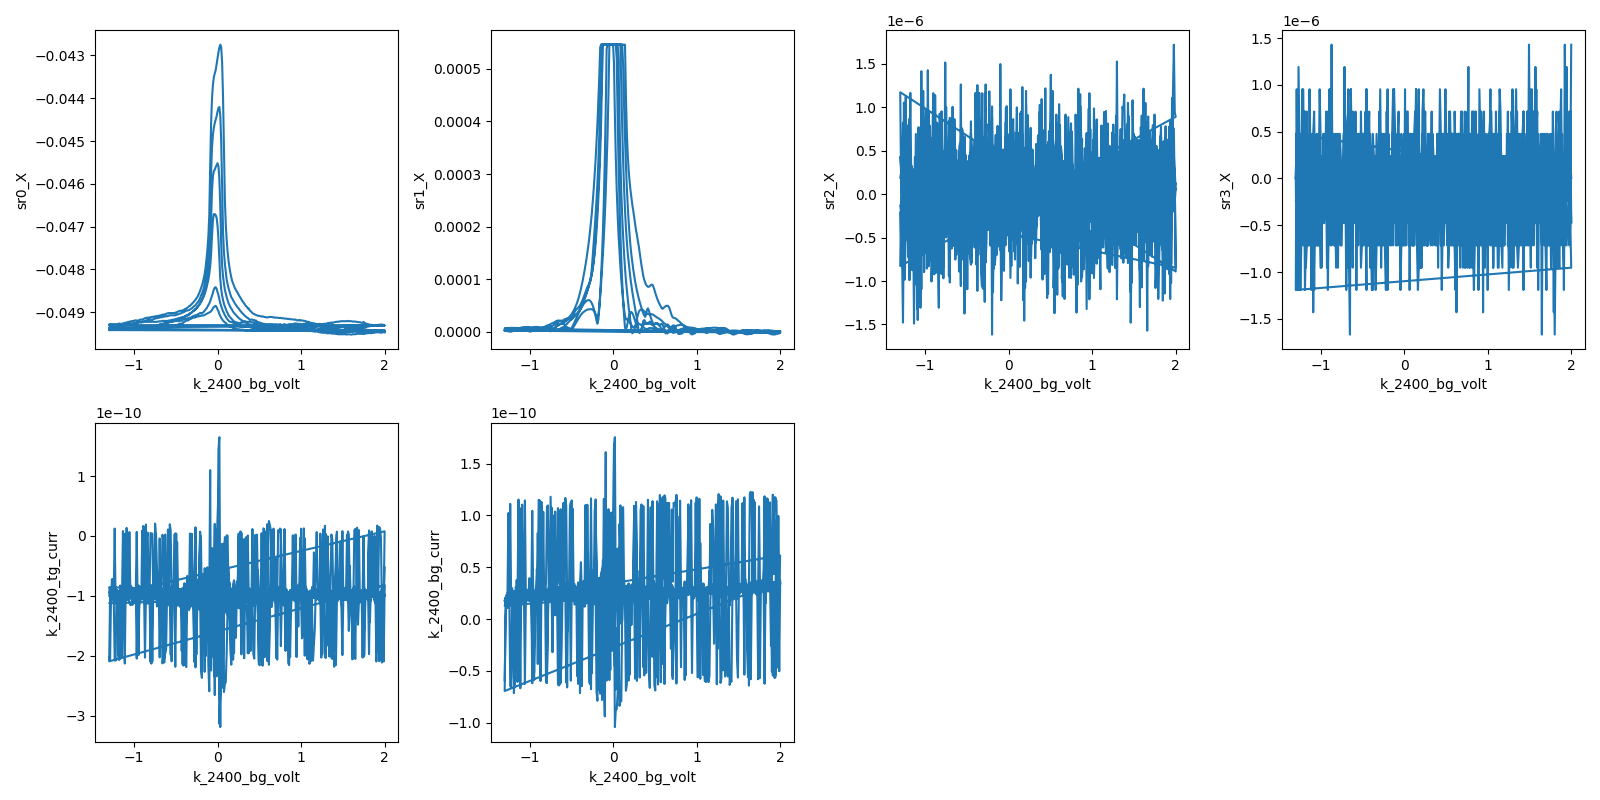

2026-08-24 21:19:28,469 [INFO] Completed in 1h 1m 42s


2026-08-24 21:19:28,471 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\6\data.tsv.gz


sweep exited at B=+1.0064 T, V_bg=+2.0000 V
2026-08-24 21:19:28,602 [INFO] Ramping k_2400_bg_volt: 2.0 -> 0


2026-08-24 21:19:31,182 [INFO] Ramping k_2400_tg_volt: 0.0215 -> 0


parked gates: V_tg=+0.0000 V, V_bg=+0.0000 V (field left at +1.0063 T for the next step)

BGFAN: done.  B=+1.0063 T, T=1.188 K


In [26]:
# HERA — back-gate calibration fan, measured on the way DOWN from 6 T.
# recipe: measurements/landau-fan-vti.md
# V_bg fast at fixed V_tg; B slow, DESCENDING 6 -> 1 T so the traverse home is
# measured rather than wasted (rig card: never re-traverse without a reason).
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vsi = dc205.voltage()
_B0, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={k_tg.volt():+.4f} V  V_bg={k_bg.volt():+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B0:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vsi) < 0.01, "V_si not at 0"
assert 5.8 <= _B0 <= 6.2, f"expected to start at 6 T, found {_B0:.4f} T"
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not 1"
assert np.isclose(sr1.time_constant(), 0.1) and abs(sr1.filter_slope() - 24) < 1, \
    "sr1 not at the committed tau/slope"
assert magnet.persistent_switch_on() and magnet.output_enabled(), "magnet not ready"

# CNP measured from run 5's ray convergence: V_tg = +0.0216 V at V_bg = 0.
# Fixing V_tg there puts the CNP at V_bg = 0, centring the fast axis on it.
V_TG_FIXED = 0.0216
B_V = np.array([6.0, 5.0, 4.0, 3.0, 2.0, 1.0])      # descending: rides the magnet home
BG_V = np.linspace(BG_MIN, BG_MAX, 301)             # 11 mV steps over the full window

assert B_V.max() <= B_SESSION_CAP, "B vector exceeds committed session cap"
assert TG_MIN <= V_TG_FIXED <= TG_MAX, "V_tg outside validator"
assert BG_V.min() >= BG_MIN and BG_V.max() <= BG_MAX, "BG vector outside validator"

print(f"grid: B {B_V[0]:.1f} -> {B_V[-1]:.1f} T x{len(B_V)} rows (descending)  [slow]")
print(f"      V_bg {BG_V[0]:+.3f} -> {BG_V[-1]:+.3f} V x{len(BG_V)} "
      f"({np.diff(BG_V)[0]*1e3:.1f} mV) at V_tg = {V_TG_FIXED:+.4f} V  [fast]")
print(f"      {len(B_V)*len(BG_V)} points; descent {5.0/0.137:.0f} min + "
      f"grid {len(B_V)*len(BG_V)*0.87/60:.0f} min")
# predicted LL spacing on the back gate, using c_bg = 0.864 * c_tg(measured)
_c_tg_meas = 2.5152e-3
_c_bg_guess = 0.864 * _c_tg_meas
_a_bg = cst.e**2 / (cst.h * _c_bg_guess)
print(f"      predicted dV_bg per dnu=4 at 6 T: {4*_a_bg*6.0:.3f} V "
      f"-> {3.3/(4*_a_bg*6.0):.1f} periods across the window, "
      f"{4*_a_bg*6.0/np.diff(BG_V)[0]:.0f} pts/period")

meas_config["comments"] = ("back-gate calibration fan on the descent from 6 T: absolute c_bg "
                           "from LL spacing + CNP line slope; both carrier signs")
meas_config["Si (V)"] = dc205.voltage()
meas_config["sample_temperature:"] = T_sample()

s = sweep.AsyncStation(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment('CALIBRATION fan #2 (back-gate lever arm), measured on the descent from 6 T')
s.add_comment(f'B slow {B_V[0]:g}..{B_V[-1]:g} T x{len(B_V)} DESCENDING; '
              f'V_bg fast {BG_V[0]:+g}..{BG_V[-1]:+g} V x{len(BG_V)} at V_tg = {V_TG_FIXED:+g} V')
s.add_comment('V_tg fixed at run 5 measured CNP (+0.0216 V at V_bg=0), so the CNP sits at V_bg=0')
s.add_comment('run 5 gave c_tg = 2.515e-3 F/m^2 (dn/dV_tg = 1.570e12 cm^-2/V) from 7 LL '
              'ray slopes in ratio 4:8:12:16:20:24, slope/nu consistent to 1.4%')
s.add_comment(f'I_bias = {I_BIAS:.4e} A, drive {sr1.amplitude()} V @ {sr1.frequency()} Hz')
s.add_comment(f'sr1 tau={sr1.time_constant()} s slope={sr1.filter_slope()} dB/oct, '
              f'fast_delay={DWELL:.2f} s, sens {sr1.sensitivity():.1e} (CNP clips, by design)')
s.add_comment('NOTE: Rxx carries a small R_xy admixture (negative R at deep minima, '
              'consistent with ~0.5% of h/8e^2) - single field polarity, not symmetrised')
s.add_comment('contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.')

s.ramp(k_tg.volt, V_TG_FIXED)
s.ramp(k_bg.volt, BG_V[0])
interruptible_sleep(10)
print(f"positioned: V_tg={k_tg.volt():+.4f}, V_bg={k_bg.volt():+.4f}, B={magnet.field():+.4f} T")

s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample).fp(T_vaporizer)
for _lia in (sr0, sr1, sr2, sr3):
    s.fp(_lia.X).fp(_lia.P)
    s.plot(k_bg.volt, _lia.X)
s.plot(k_bg.volt, k_tg.curr)
s.plot(k_bg.volt, k_bg.curr)

try:
    s.megasweep(magnet.field, B_V, k_bg.volt, BG_V, slow_delay=2.0, fast_delay=DWELL)
finally:
    print(f"sweep exited at B={magnet.field():+.4f} T, V_bg={k_bg.volt():+.4f} V")
    s.ramp(k_bg.volt, 0)
    s.ramp(k_tg.volt, 0)
    print(f"parked gates: V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V "
          f"(field left at {magnet.field():+.4f} T for the next step)")

print(f"\nBGFAN: done.  B={magnet.field():+.4f} T, T={T_sample():.3f} K")


## HERA — SdH spot check on the measured D = 0 line (investigation Step 3)

> **21:20** · SdH spot check, investigation Step 3: 5 fixed (n, D=0) points [n = -0.9, +1.8, +2.2, +2.6, +3.0 e12 cm^-2] on the session-measured calibration, B slow 1.5->6.0 T uniform-B at dB = d(1/B)\*B\_lo^2 (Nyquist x3 on F\_L=32 T), fast\_delay=0.70 s, sr1 re-ranged to 1e-4 for FFT resolution · **ETA ~22:30** (≈1h10m)

`recipe: measurements/sdh-spot-check.md`. First measurement of the session that
is *science* rather than calibration — everything before it existed to make this
one interpretable.

**The calibration is closed.** Run 6's back-gate rays give α_bg = 0.01850 V/(T·ν)
→ **dn/dV_bg = 1.307×10¹² cm⁻²/V** (6% slope scatter over 7 rays; implied
back-gate hBN 12.7 nm vs the card's 11.0). With run 5's top gate that gives

> **c_bg/c_tg = 0.832 (measured)** — against the geometry prior 0.864, and
> against the **0.58–0.67** the zero-field ridge slopes implied.

That agreement with geometry, and disagreement with the ridges, is the
independent confirmation that the zero-field ridges were never CNP lines. The
(n, D) frame is now data-grade in *both* lever arms — the
`cnp-and-dline-calibration` Step-5 upgrade, completed.

Run 6's ray **intercepts** are much weaker than run 5's (3/7 within tolerance,
V_CNP(bg) = +0.039 ± 0.034 V vs run 5's ±0.008), which is expected: this cut
sweeps D from +0.16 to −0.24 V/nm, so the gap opens along it and LL character
changes. **Slopes are robust to that, intercepts are not** — so the lever arm is
taken from run 6 and the CNP from run 5.

**Design densities, and the range verdict.** D = 0 is V_bg = V_tg/0.832, and
along it n = 3.14·V_tg − 0.032 (10¹² cm⁻²), giving a reachable window of
**n ∈ [−0.97, +3.11]×10¹² cm⁻²**. So the **electron side reaches the
|n| ≳ 2–3×10¹² window where the ABAB and ABCA templates separate; the hole side
does not** — it tops out at −0.97×10¹², inside the exception regime where the
ABAB pair collapses toward a single tone near 0.95·F_L and genuinely mimics an
ABCA singleton. Five points are taken: **n = +1.8, +2.2, +2.6, +3.0** on the
electron side (spanning into the design window so the n-dependence of any tone
is visible), plus **n = −0.9** so the hole side gets its spot check as the
investigation requires — reported for what it is, a range-limited look, not a
comparable measurement.

**All five ride one traverse.** B is the slow axis and the five (V_tg, V_bg)
pairs are the fast axis, so the magnet ramps once per field row and every
density is sampled at every field — five spot checks for one magnet traverse
instead of five.

**Sampling, computed not guessed** (recipe Step 2). F_L = (h/4e)·n at the
largest |n| is ≈32 T. The magnet is blocking and rate-limited, so the recipe's
blocking branch applies: sample **uniformly in B** with ΔB = Δ(1/B)·B_lo², taking
Δ(1/B) at Nyquist×3 on F_L. B runs 1.5 → 6.0 T. B_lo = 1.5 rather than lower
because ΔB scales as B_lo² and a deeper floor multiplies the row count — the
onset region below 1.5 T is already characterised by runs 5/6, which show
oscillations developing by 1 T and minima reaching 6.6 Ω at 1.5 T.

**`sr1` re-ranged to 100 µV.** The 500 µV range used for the fans put the
metallic signal at ~2% of full scale, which is exactly the recipe's grainy-FFT
failure mode ("a signal at a few % of range is coarse-ADC digitized"). Away from
the CNP R_xx runs 50–300 Ω, so 100 µV puts full scale near 2 kΩ and the signal
at ~10% — quantisation drops to ~0.03 Ω, well under any oscillation amplitude
worth resolving.

**Stated assumption:** D_offset = 0. No feature has yet been found that
physically locates D = 0 on this device, so "D = 0" here means "the
capacitance-symmetric line through the measured CNP". The recipe requires this
be said out loud rather than assumed silently.

**Carried caveat:** R_xx includes a ~1% R_xy admixture (negative R at deep
minima, scaling with h/νe² as expected), and every run this session is
single-polarity, so no ±B symmetrisation is possible. For frequency *content*
this is benign; for any amplitude-based claim it is not.

**Cost:** traverse 4.5 T / 0.137 ≈ 33 min, plus one 3 s magnet settle per row,
plus the grid. **ETA 1h10m**, ending at 6 T.


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+1.0064 T  T_sample=1.188 K

(n, D=0) targets on the measured calibration:
  n = -0.90e12  ->  V_tg = -0.2765 V, V_bg = -0.3321 V   (closure check: n = -0.900e12)
  n = +1.80e12  ->  V_tg = +0.5834 V, V_bg = +0.7008 V   (closure check: n = +1.800e12)
  n = +2.20e12  ->  V_tg = +0.7108 V, V_bg = +0.8538 V   (closure check: n = +2.200e12)
  n = +2.60e12  ->  V_tg = +0.8382 V, V_bg = +1.0068 V   (closure check: n = +2.600e12)
  n = +3.00e12  ->  V_tg = +0.9656 V, V_bg = +1.1599 V   (closure check: n = +3.000e12)

sampling: F_L(max |n|) = 31.0 T -> d(1/B) = 0.01075 1/T (Nyquist x3) -> dB = 0.0242 T
  B 1.5 -> 6.0 T, 187 rows; d(1/B) at B_lo = 0.01075, at B_hi = 0.00067 1/T
  usable-record resolution dF = 1/(1/B_lo - 1/B_hi) = 2.00 T
  cost: traverse 33 min + 187 settles x3 s = 9 min + grid 14 min



sr1 re-ranged to 1.0e-04 V (R ceiling 2.03 kohm); tau=0.1 s, slope=24 dB/oct, dwell=0.70 s
2026-08-24 21:20:54,300 [INFO] Ramping k_2400_tg_volt: 0.0 -> -0.27647420382165605


2026-08-24 21:20:54,710 [INFO] Ramping k_2400_bg_volt: 0.0 -> -0.3321074980872226


positioned: V_tg=-0.2765, V_bg=-0.3320, B=+1.0064 T
2026-08-24 21:21:05,274 [INFO] Starting multimegasweep with ID 7


2026-08-24 21:21:05,275 [INFO] Minimum duration 0h 14m 1s


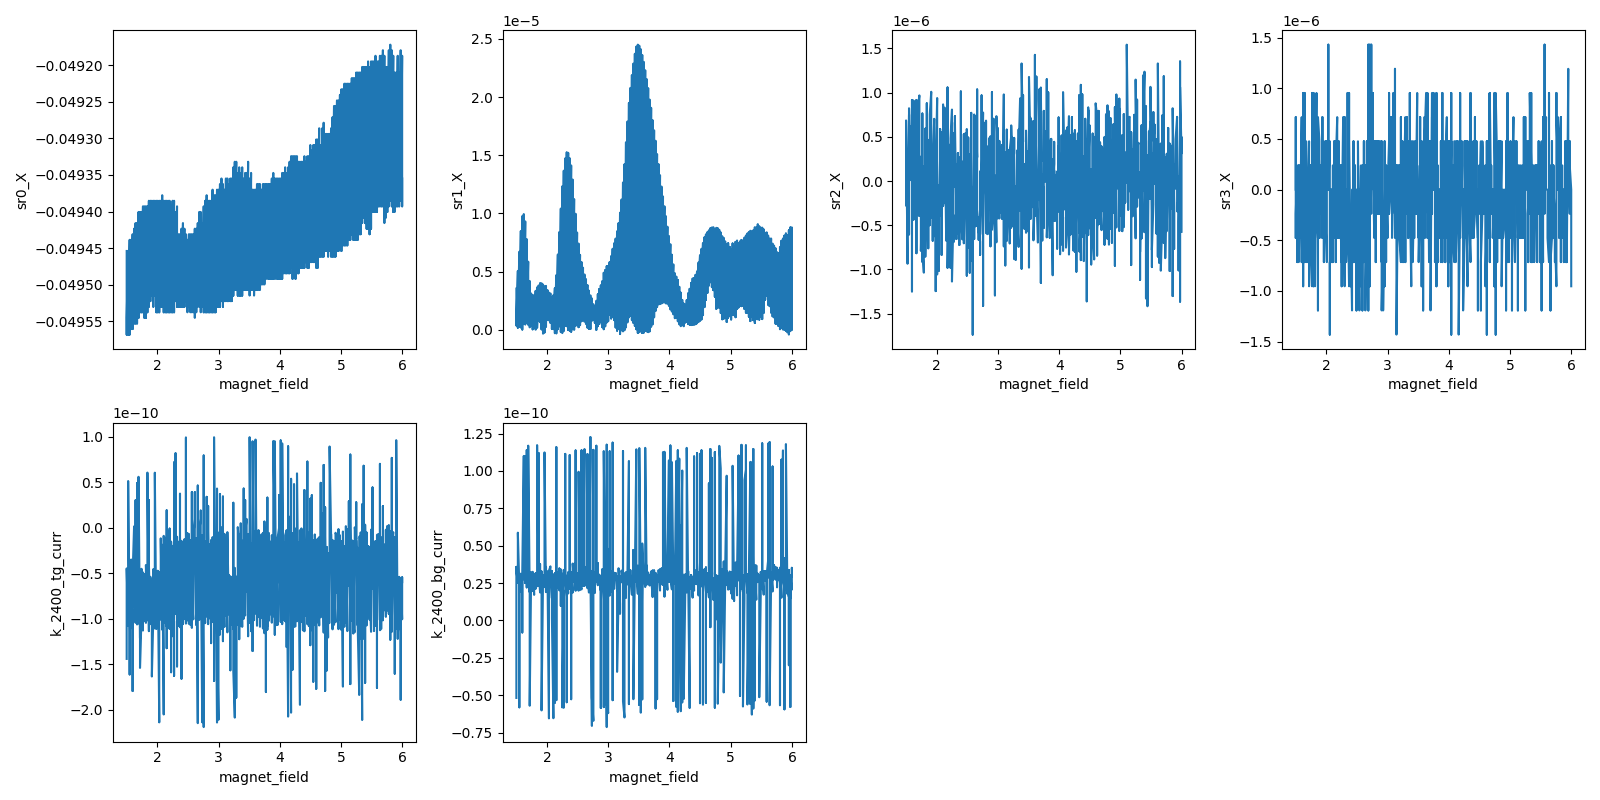

2026-08-24 22:43:55,653 [INFO] Completed in 1h 22m 49s


2026-08-24 22:43:55,655 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\7\data.tsv.gz


sweep exited at B=+6.0038 T
2026-08-24 22:43:55,718 [INFO] Ramping k_2400_tg_volt: 0.9655 -> 0


2026-08-24 22:43:57,002 [INFO] Ramping k_2400_bg_volt: 1.16 -> 0


parked gates: V_tg=+0.0000 V, V_bg=+0.0000 V

SPOTCHECK: done.  B=+6.0037 T, T=1.263 K


In [27]:
# HERA — SdH spot check on the measured D = 0 line.
# recipe: measurements/sdh-spot-check.md (+ field-sweep-1d call surface)
# B slow (magnet ramps once per row), 5 fixed (n, D=0) gate points fast, so all
# five densities ride the SAME traverse.
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vsi = dc205.voltage()
_B0, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={k_tg.volt():+.4f} V  V_bg={k_bg.volt():+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B0:+.4f} T  T_sample={_Ts:.3f} K")
assert abs(_vsi) < 0.01, "V_si not at 0"
assert 0.8 <= _B0 <= 1.2, f"expected to start near 1 T (end of run 6), found {_B0:.4f} T"
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not 1"
assert magnet.persistent_switch_on() and magnet.output_enabled(), "magnet not ready"

# ---- calibration, measured this session (runs 5 and 6) ----
DN_DVTG = 1.570e12      # cm^-2 / V   (run 5, 7 LL ray slopes, 1.4% scatter)
DN_DVBG = 1.307e12      # cm^-2 / V   (run 6, 7 LL ray slopes, 6% scatter)
V_TG_CNP, V_BG_CNP = 0.0203, 0.0      # run 5 ray convergence, +/- 0.0076 V
RATIO = DN_DVBG / DN_DVTG             # c_bg/c_tg = 0.832 measured
# D = 0 (assuming D_offset = 0 -- an UNEXAMINED assumption, stated per recipe):
#   c_tg*V_tg = c_bg*V_bg  ->  V_bg = V_tg / RATIO
N_TARGETS = np.array([-0.9, 1.8, 2.2, 2.6, 3.0])      # 1e12 cm^-2
V_TGS = (N_TARGETS * 1e12 + DN_DVTG * V_TG_CNP) / (DN_DVTG + DN_DVBG / RATIO)
V_BGS = V_TGS / RATIO

print("\n(n, D=0) targets on the measured calibration:")
for n_, vt, vb in zip(N_TARGETS, V_TGS, V_BGS):
    n_chk = (DN_DVTG * (vt - V_TG_CNP) + DN_DVBG * (vb - V_BG_CNP)) / 1e12
    print(f"  n = {n_:+5.2f}e12  ->  V_tg = {vt:+.4f} V, V_bg = {vb:+.4f} V   "
          f"(closure check: n = {n_chk:+.3f}e12)")
assert V_TGS.min() >= TG_MIN and V_TGS.max() <= TG_MAX, "V_tg targets outside validator"
assert V_BGS.min() >= BG_MIN and V_BGS.max() <= BG_MAX, "V_bg targets outside validator"

# ---- field grid: uniform in B with dB = d(1/B)*B_lo^2 (blocking magnet) ----
B_LO, B_HI = 1.5, 6.0
F_L_MAX = cst.h / (4 * cst.e) * np.abs(N_TARGETS).max() * 1e16      # Tesla
D_INVB = 1.0 / (3 * F_L_MAX)                                        # Nyquist x3 on F_L
DB = D_INVB * B_LO ** 2
B_V = np.arange(B_LO, B_HI + 1e-9, DB)
assert B_V.max() <= B_SESSION_CAP, "B vector exceeds committed session cap"
print(f"\nsampling: F_L(max |n|) = {F_L_MAX:.1f} T -> d(1/B) = {D_INVB:.5f} 1/T "
      f"(Nyquist x3) -> dB = {DB:.4f} T")
print(f"  B {B_LO} -> {B_HI} T, {len(B_V)} rows; d(1/B) at B_lo = {DB/B_LO**2:.5f}, "
      f"at B_hi = {DB/B_HI**2:.5f} 1/T")
print(f"  usable-record resolution dF = 1/(1/B_lo - 1/B_hi) = "
      f"{1/(1/B_LO - 1/B_HI):.2f} T")
print(f"  cost: traverse {(B_HI-B_LO)/0.137:.0f} min + {len(B_V)} settles x3 s "
      f"= {len(B_V)*3/60:.0f} min + grid {len(B_V)*len(V_TGS)*0.87/60:.0f} min")

# ---- lock-in range: sens ~ I_bias * R_target, NOT the wide CNP range ----
# recipe: "a signal at a few % of range is coarse-ADC digitized (grainy-FFT)".
# Away from the CNP R_xx runs ~50-300 ohm; 1e-4 puts full scale at ~2 kohm.
sr1.sensitivity(1e-4)
interruptible_sleep(2.0)
print(f"\nsr1 re-ranged to {sr1.sensitivity():.1e} V (R ceiling "
      f"{sr1.sensitivity()/abs(I_BIAS)/1e3:.2f} kohm); tau={sr1.time_constant()} s, "
      f"slope={sr1.filter_slope()} dB/oct, dwell={DWELL:.2f} s")

meas_config["comments"] = ("SdH spot check on the measured D=0 line, 5 densities "
                           "(-0.9, 1.8, 2.2, 2.6, 3.0 e12 cm^-2), B 1.5-6 T uniform-B")
meas_config["Si (V)"] = dc205.voltage()
meas_config["sample_temperature:"] = T_sample()

s = sweep.AsyncStation(meas_config)
s.add_comment('sdh-spot-check')
s.add_comment('5 fixed (n, D=0) points share one traverse; B slow so the magnet ramps per row')
s.add_comment(f'n targets (1e12 cm^-2): {N_TARGETS.tolist()}')
s.add_comment(f'V_tg: {[round(v,4) for v in V_TGS]}')
s.add_comment(f'V_bg: {[round(v,4) for v in V_BGS]}')
s.add_comment(f'calibration THIS SESSION: dn/dV_tg={DN_DVTG:.3e}, dn/dV_bg={DN_DVBG:.3e} cm^-2/V, '
              f'c_bg/c_tg={RATIO:.4f}, CNP at V_tg={V_TG_CNP:+.4f} V (V_bg=0) '
              '-- from LL ray slopes/convergence, runs 5 and 6')
s.add_comment('D_offset = 0 is an UNEXAMINED assumption (no feature yet locates D=0 physically)')
s.add_comment(f'B {B_LO}..{B_HI} T uniform-B, dB={DB:.4f} T = d(1/B)*B_lo^2, '
              f'{len(B_V)} rows; Nyquist x3 on F_L={F_L_MAX:.1f} T')
s.add_comment(f'I_bias = {I_BIAS:.4e} A; sr1 sens {sr1.sensitivity():.1e} sized to R_target '
              f'(not the wide CNP range) per the recipe grainy-FFT warning')
s.add_comment('Rxx carries ~1% R_xy admixture; single field polarity, NOT symmetrised')
s.add_comment('contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.')

s.ramp(k_tg.volt, float(V_TGS[0]))
s.ramp(k_bg.volt, float(V_BGS[0]))
interruptible_sleep(10)
print(f"positioned: V_tg={k_tg.volt():+.4f}, V_bg={k_bg.volt():+.4f}, B={magnet.field():+.4f} T")

s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample).fp(T_vaporizer)
for _lia in (sr0, sr1, sr2, sr3):
    s.fp(_lia.X).fp(_lia.P)
    s.plot(magnet.field, _lia.X)
s.plot(magnet.field, k_tg.curr)
s.plot(magnet.field, k_bg.curr)

try:
    s.multimegasweep([magnet.field], [B_V], [k_tg.volt, k_bg.volt], [V_TGS, V_BGS],
                     slow_delay=1.0, fast_delay=DWELL)
finally:
    print(f"sweep exited at B={magnet.field():+.4f} T")
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
    print(f"parked gates: V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V")

print(f"\nSPOTCHECK: done.  B={magnet.field():+.4f} T, T={T_sample():.3f} K")


## HERA — session close-out (`return-to-initial`)

> **22:49** · Close-out, return-to-initial: field -> 0.0 T, restore=state0 (drive 5.0->1.0 V, lock-in sens/tau/slope to bring-up), heaters off, gates + Si parked via k\_si; no mux (hardwired) · **ETA ~22:59** (≈10 min)

`recipe: utils/session-closeout.md` + `utils/session-closeout-vti.md`. The
brief's close-out ask is **`return-to-initial`**: replay the bring-up capture so
the next run starts from the state this session started from.

- **Field → 0.0 T**, the session-start value (VERIFY read +0.0063 T). Explicit in
  the call, as the tool requires — the endpoint never arrives via `restore=`.
  From 1 T that is a ~7 min blocking ramp. The last two measurement runs were
  deliberately planned to *end* low (run 6 rode the magnet 6 → 1 T as a measured
  descent) precisely so this ramp would be short — the rig card's "plan the
  session's last sweep to end at the endpoint".
- **`restore=state0`** replays the bring-up capture: drive amplitude back to
  1.0 V from the 5.0 V this session committed, all four lock-ins' sensitivity /
  τ / filter slope back to their bring-up values, gates to 0. Everything this
  session changed on the rack was an acquisition setting, and all of it is in
  `state0`.
- **Heaters off** via the labelled callable — closed-loop LS335, so
  `heater.off("both")` drops both ranges (VTI variant). They were never on; this
  is belt-and-braces and the readback confirms nothing is lifting.
- **Si parks through `k_si`** (`smart_voltage`), never raw `voltage`, so the
  driver paces the set at `ramp_rate` — the VTI variant's Si-dielectric rule.
- **No `mux=`**: hardwired breakout this cooldown, so there is nothing to park.
- **Persistent switch and output are untouched** — operator-only per the rig
  card; close-out never touches them.

The readback that this prints is the handoff record and goes into
`session_notes.md` under Session close / handoff, together with the device-card
end-state block.


In [ ]:
# HERA — session close-out. Ask: return-to-initial (session brief).
# recipe: utils/session-closeout.md + session-closeout-vti.md
#   - field endpoint = the session-start field (VERIFY read +0.0063 T -> 0.0)
#   - restore = state0, the bring-up capture (drive back to 1.0 V, lock-in
#     sens/tau/slope back to bring-up values, gates to 0)
#   - heaters off via the labelled callable (closed-loop LS335, VTI variant)
#   - Si parks through k_si / smart_voltage, never raw voltage (VTI variant)
#   - no mux= : hardwired breakout this cooldown
#   - persistent switch / output are operator-only; close-out never touches them
from sharpelab_nb.closeout import close_out

print(f"pre-closeout: B={magnet.field():+.4f} T, V_tg={k_tg.volt():+.4f}, "
      f"V_bg={k_bg.volt():+.4f}, V_si={dc205.voltage():+.4f}, "
      f"T_sample={T_sample():.3f} K, T_vap={T_vaporizer():.3f} K")
print(f"ramp home from {magnet.field():+.3f} T at 0.137 T/min ~ "
      f"{abs(magnet.field())/0.137:.0f} min")

close_out(
    (magnet.field, 0.0),
    restore=state0,
    heaters=[("LS335 ranges off", lambda: heater.off("both"))],
    gates=[(k_tg.volt, 0.0), (k_bg.volt, 0.0), (k_si, 0.0)],
    extra_readback={
        "T_sample": T_sample, "T_vaporizer": T_vaporizer,
        "I_tg": k_tg.curr, "I_bg": k_bg.curr,
        "sample_range": heater.sample_range, "vaporizer_range": heater.vaporizer_range,
    },
)


pre-closeout: B=+6.0038 T, V_tg=+0.0000, V_bg=+0.0000, V_si=+0.0000, T_sample=1.263 K, T_vap=1.052 K
ramp home from +6.004 T at 0.137 T/min ~ 44 min
-- restore (19 params)
-- heaters
   LS335 ranges off
-- gates


-- field -> 0.0


## HERA — post-interrupt state read

Operator instruction mid-close-out: **interrupt, go to high field, run the fan
ramping down.** Good call — it saves roughly half an hour of magnet time. The
previous plan let close-out land at 0 T, ramped back up to 1 T, swept up to 8 T,
and would then have needed a 58 min ramp home; going straight up and sweeping
*down* ends the fan near zero, which is the rig card's "plan the direction so the
fan ends where the next measurement needs it".

The close-out cell above was interrupted mid field-ramp and is therefore
**incomplete**: its stages run restore → excitation → heaters → gates → mux →
field, so everything except the field endpoint completed. The rack is at bring-up
values and the gates are parked, but no close-out readback was printed, so there
is no handoff record from it and **this session is not closed out**.

**The rig-card fact this turns on:** interrupting the cell does *not* stop the
supply — it keeps ramping to its last setpoint (0 T). There is no abort or
ramp-to-zero method; recovery is calling `field()` again with a new target, which
the fan cell does when it positions to 8 T. This cell is read-only and only
establishes where we actually are, including a two-point field read to confirm
the magnet is still moving and in which direction.


In [29]:
# HERA — post-interrupt state read. READ-ONLY. No sets, no ramps.
# The close-out cell was interrupted mid field-ramp on operator instruction.
# Rig card: an interrupt does NOT stop the supply - it keeps ramping to its last
# setpoint (0 T here). Recovery is calling field() again with a new target, which
# the fan cell does. This cell only establishes what state we are actually in.
import time

_b1 = magnet.field()
time.sleep(4.0)
_b2 = magnet.field()
print(f"field: {_b1:+.4f} T -> {_b2:+.4f} T over 4 s  "
      f"({(_b2-_b1)/4*60:+.3f} T/min; still ramping toward 0 as expected)")
print(f"is_ramping   : {magnet.is_ramping()}")
print(f"commanded    : {magnet.commanded_field}")
print(f"output/PS    : output={magnet.output_enabled()}, PS={magnet.persistent_switch_on()}")
print(f"gates        : V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V, "
      f"V_si={dc205.voltage():+.4f} V")
print(f"gate current : I_tg={k_tg.curr():.3e} A, I_bg={k_bg.curr():.3e} A  (nplci "
      f"{k_tg.nplci():.0f}/{k_bg.nplci():.0f})")
print(f"heaters      : sample_range={heater.sample_range()}, "
      f"vaporizer_range={heater.vaporizer_range()}")
print(f"temperature  : T_sample={T_sample():.3f} K, T_vaporizer={T_vaporizer():.3f} K")
print(f"drive        : {sr1.amplitude()} V @ {sr1.frequency()} Hz")
for _n, _s in (("sr0", sr0), ("sr1", sr1)):
    print(f"  {_n}: sens={_s.sensitivity():.3e}, tau={_s.time_constant()} s, "
          f"slope={_s.filter_slope()} dB/oct")
print()
print("close-out status: restore/heaters/gates stages COMPLETED before the field ramp")
print("  (close_out order is restore -> excitation -> heaters -> gates -> mux -> field),")
print("  so the rack is at bring-up values and the gates are parked; only the field")
print("  endpoint did not land. The fan cell re-establishes acquisition and redirects")
print("  the magnet to 8 T, so nothing here needs undoing.")
print("POST-INTERRUPT-READ: done")


field: +1.7332 T -> +1.7240 T over 4 s  (-0.137 T/min; still ramping toward 0 as expected)
is_ramping   : True
commanded    : 0.0
output/PS    : output=True, PS=True
gates        : V_tg=+0.0000 V, V_bg=+0.0000 V, V_si=+0.0000 V


gate current : I_tg=-9.904e-11 A, I_bg=2.670e-11 A  (nplci 1/1)
heaters      : sample_range=0, vaporizer_range=0
temperature  : T_sample=1.207 K, T_vaporizer=0.993 K
drive        : 1.0 V @ 13.777 Hz
  sr0: sens=2.000e-02, tau=0.3 s, slope=24 dB/oct
  sr1: sens=2.000e-06, tau=0.3 s, slope=24 dB/oct

close-out status: restore/heaters/gates stages COMPLETED before the field ramp
  (close_out order is restore -> excitation -> heaters -> gates -> mux -> field),
  so the rack is at bring-up values and the gates are parked; only the field
  endpoint did not land. The fan cell re-establishes acquisition and redirects
  the magnet to 8 T, so nothing here needs undoing.
POST-INTERRUPT-READ: done


## HERA — electron-side Landau fan at D = 0, uniform in 1/B, τ = 300 ms

> **23:22** · FS-count fan (Step 4/5): B slow 8.0->1.0 T x101 DESCENDING uniform in 1/B (d(1/B)=0.00875, dF=1.143 T), n fast +1.20->+3.05e12 x57 at D=0, tau=300ms/24dB, fast\_delay=2.10 s, slow\_delay=2.5 s, I\_bias=49.2 nA, sr1 sens 1e-4; redirects the magnet off the interrupted close-out ramp to 8 T first · **ETA ~05:07 (+1d)** (≈5h45m)

`recipe: measurements/landau-fan-vti.md` — the investigation's **Step 4/5** fan.
Operator-directed: τ = 300 ms, B 1 → 8 T sampled in 1/B, much finer B, 4–6 h,
to firm the call. This is the measurement run 7 could only gesture at.

**What run 7 left unresolved, and how each parameter here attacks it.**

The spot check gave *ABAB (consistent-with)* — a pair at n = +3.0 summing to F_L
within 2% with partition 0.245/0.755 (model ABAB: 0.215/0.785; trilayer excluded
5×), and an F_L tone that is the pair's sum. Three things stopped it being a
call, and this fan is built against them:

1. **Partner tones reproduced in only 3–9 of 18 extraction choices** (vs 15–16/18
   for the dominant tone). → **τ = 300 ms** is the fix. Measured on this device
   at 5 V drive: point-to-point scatter 0.14% of R_xx at τ = 0.3 s vs 0.35% at
   τ = 0.1 s (cells 39/41) — **2.5× the SNR**, aimed precisely at the weak
   partner. Costs 2.1 s/point at the 24 dB/oct settling floor, which is what the
   4–6 h budget buys.
2. **The Luttinger sum closed at only 2 of 4 densities.** → **81 density columns**
   instead of 5. f₁(n) + f₂(n) = F_L(n) across density is *algebraic* — no model —
   and a coincidental match cannot hold across 81 columns. This is the
   investigation's Step-5 partition-robustness test, and it is the strongest
   evidence available without a mass measurement.
3. **The F_L-tone origin split was resolution-limited and therefore unreadable.**
   My high-B half had δF = 10 T against an 8 T tone separation, so "only the F_L
   tone survives at high B" could not be distinguished from "the two tones merged".
   → **Uniform 1/B sampling fixes this structurally.** Splitting the record at
   the 1/B midpoint (B = 1.78 T) gives the two halves **equal** Δ(1/B) span and
   therefore **equal δF = 2.29 T** — against an ABAB pair separation of 17.7 T,
   which is 7.7× that. **Both fundamentals and the sum tone are resolved in both
   halves**, so the breakdown test (does the F_L tone strengthen with B relative
   to the fundamentals?) becomes decisive rather than suggestive.

**Grid — descending, ≥ 100 rows.** B: `field_invB(8.0, 1.0, 101)` — **101 rows
sweeping 8 → 1 T**, uniform in 1/B at Δ(1/B) = 0.00875 T⁻¹. That is finer than
the recipe's *preferred* 1/(3·F_L) = 0.01057 at the top density, giving **57 T
resolvable = 1.81 × F_L** — comfortable headroom above the fastest expected tone.
ΔB runs 0.0088 T at the low-field end to 0.62 T at the top, which is the point:
constant points-per-period in 1/B, and `sdh_fft` receives an already-even record
with no resampling. Usable-record resolution **δF = 1.143 T** against run 7's
2.00 T; the partner tone (6.67 T predicted at n = 3×10¹²) gets **5.8 periods**,
clearing the recipe's ≥ 5.

**Direction is the operator's call and it is the right one.** Starting high and
sweeping down means the traverse home *is* the measurement — the fan ends at 1 T,
a 7 min ramp from parked, instead of ending at 8 T and owing a 58 min ramp. Net
saving against the ascending plan is roughly half an hour of magnet time, and it
is exactly the base recipe's "plan the direction so the fan ends where the next
measurement needs it".

n: 57 columns from **+1.20 to +3.05 × 10¹²** cm⁻² along the measured D = 0 line
(V_bg = V_tg/0.8324), spanning from below into the |n| ≳ 2–3×10¹² window where
the ABAB and ABCA templates separate — so the *trajectory* of the partition is
measured, not just its value at one point. The low end stops at +1.2×10¹² rather
than at the CNP because below that the top of the field range enters low filling
factor (ν ≈ 6 at 8 T) where the SdH frequency picture degrades into quantum Hall,
and those columns would cost time without carrying frequency content.

**Acquisition re-established.** Close-out restored bring-up values, so the cell
sets drive back to 5.0 V (I ≈ 49.2 nA — linearity verified to 0.84% over a 5×
current range, cell 41), τ = 0.3 s / 24 dB/oct on both channels, `sr0` at 200 mV
and `sr1` at **100 µV** (R ceiling ≈ 2 kΩ; the electron flank runs 10–400 Ω, so
the signal sits at ~10% of range rather than the fans' 2% — the recipe's
grainy-FFT warning).

**Cost:** ramp-in from wherever the interrupted close-out left the field up to
8 T ≈ 47 min, traverse 8 → 1 T ≈ 51 min, 101 magnet settles ≈ 5 min, grid
101 × 57 × 2.25 s ≈ 3.6 h. **Estimate 5.43 h, ETA 5h45m** with this rig's
habitual 5–10% over-run. **Ends at 1 T**, leaving a 7 min ramp to close out.

The column count (57, down from the 81 of the ascending plan) is what pays for
the ≥ 100 field rows and the 47 min ramp-in. Δn = 0.033×10¹² between columns is
still far finer than any structure in F(n), so the trajectory test loses nothing.

**Carried caveat, with a useful sharpening.** R_xx still contains ~1% R_xy
admixture and this is again a single field polarity, so no ±B symmetrisation.
But R_xy is periodic in 1/B at the *same* fundamental as R_xx — it distorts the
waveform, adding harmonic content, and does **not** create new fundamental
frequencies. So the pair positions and the Luttinger partition (fundamentals)
are robust to it; the harmonic structure, including the 50.2 and 55.5 T tones
left unexplained in run 7, is not. Any claim resting on harmonics stays hedged.

**Recovering the magnet.** The close-out cell was interrupted mid field-ramp, so
the supply is still heading for 0 T — on this rig an interrupt stops the *cell*,
not the supply, and the only recovery is a fresh blocking set with a new target.
The cell issues that set explicitly (rather than letting the sweep's first slow
point do it silently) so the redirect and its cost are on the page.

**Checkpoints:** first rows for railing/leakage and a per-point re-price against
the 2.25 s assumption; then periodically. Note the descent means the *high-field*
rows land first, so early columns will show the sharpest LL structure but the 1/B
record only becomes long enough to resolve the pair once the sweep has worked
down past ~2 T — per-column FFT is a late-run read, not a halfway one.


preconditions: V_tg=+0.0000 V  V_bg=+0.0000 V  V_si=+0.0000 V  B=+1.4872 T  T_sample=1.202 K  T_vap=0.987 K


acquisition: drive=5.0 V @ 13.777 Hz -> I=4.8355e-08 A; tau=0.3 s, slope=24 dB/oct, dwell=2.10 s
             sr0 sens=2.00e-01 (load 0.242), sr1 sens=1.00e-04 (R ceiling 2.07 kohm)

grid: B 8.00 -> 1.00 T x101 rows, UNIFORM IN 1/B (d(1/B) = 0.008750 1/T)  [slow]
      dB = 0.5234 T at the low end, 0.0088 T at the high end
      n 1.20 -> 3.05 e12 cm^-2 x57 cols (dn = 0.0330e12), D = 0  [fast]
      V_tg 0.3923 -> 0.9815 V; V_bg 0.4713 -> 1.1790 V
sampling: F_L(n_max) = 31.53 T; Nyquist needs d(1/B) <= 0.01586, prefer 0.01057; have 0.00875  -> 57.1 T resolvable (1.81 x F_L)
resolution: dF = -1.143 T   (run 7 spot check had 2.00 T)
B-window split at B = 1.778 T: halves have EQUAL d(1/B) span -> dF_half = -2.29 T each; the ABAB pair separation (17.7 T at n=3e12) is -7.7x that, so BOTH tones resolve in BOTH halves
partner tone gets -5.8 periods in the record (recipe wants >= 5)
points: 5757; estimated 5.44 h (ramp-in 48m + traverse 51m + grid 216m)
2026-08-24 23:22:40,858 [INFO] Ramping k

2026-08-24 23:22:41,410 [INFO] Ramping k_2400_bg_volt: 0.0 -> 0.47125899005355776



positioned gates: V_tg=+0.3925, V_bg=+0.4715
field now +1.4484 T, commanded 0.0 -> redirecting to 8.00 T (~48 min blocking ramp)


at field: B=+8.0065 T, T_sample=1.285 K, T_vap=1.072 K; starting the descent
2026-08-25 00:10:48,099 [INFO] Starting multimegasweep with ID 8


2026-08-25 00:10:48,100 [INFO] Minimum duration 3h 25m 42s


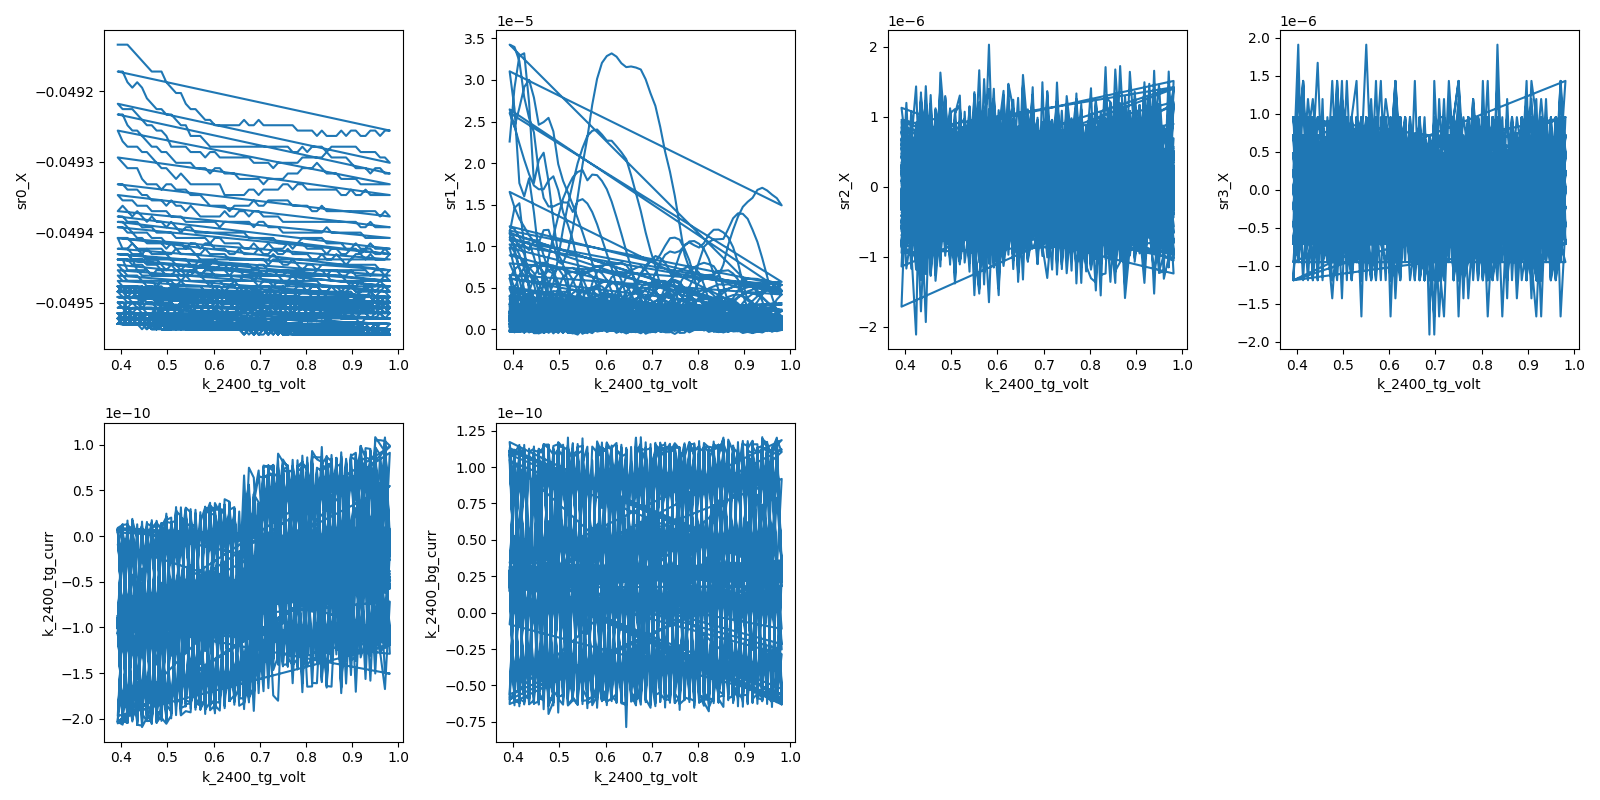

2026-08-25 04:47:06,815 [INFO] Completed in 4h 36m 17s


2026-08-25 04:47:06,815 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260825-vti-02\data\8\data.tsv.gz


sweep exited at B=+1.0063 T
2026-08-25 04:47:06,880 [INFO] Ramping k_2400_tg_volt: 0.9815 -> 0


2026-08-25 04:47:08,181 [INFO] Ramping k_2400_bg_volt: 1.179 -> 0


parked gates: V_tg=+0.0000 V, V_bg=+0.0000 V; field left at +1.0064 T

BIGFAN: done.  B=+1.0064 T, T=1.187 K


In [30]:
# HERA — electron-side Landau fan at D = 0, uniform in 1/B, tau = 300 ms.
# recipe: measurements/landau-fan-vti.md (investigation Step 4/5)
# Operator-directed: tau=300ms, B 1-8 T sampled in 1/B, much finer B, 4-6 h.
import numpy as np

# --- preconditions this cell assumes but does not set ---
_vsi = dc205.voltage()
_B0, _Ts = magnet.field(), T_sample()
print(f"preconditions: V_tg={k_tg.volt():+.4f} V  V_bg={k_bg.volt():+.4f} V  V_si={_vsi:+.4f} V  "
      f"B={_B0:+.4f} T  T_sample={_Ts:.3f} K  T_vap={T_vaporizer():.3f} K")
assert abs(_vsi) < 0.01, "V_si not at 0"
assert abs(_B0) <= 8.5, "unexpected field"   # close-out was interrupted mid-ramp;
# the supply is still heading for 0 (rig card: interrupt != stop). We redirect below.
assert 1.0 <= _Ts <= 1.4, "sample not at base"
assert k_tg.nplci() == 1 and k_bg.nplci() == 1, "gate-current nplci not 1"
assert magnet.persistent_switch_on() and magnet.output_enabled(), "magnet not ready"
assert int(heater.sample_range()) == 0 and int(heater.vaporizer_range()) == 0, "heaters not off"

# --- acquisition config: close-out restored bring-up values, so re-establish ---
# tau = 300 ms is the operator's call and it is the right one: at 5 V drive the
# measured point-to-point scatter was 0.14% of R_xx at tau=0.3 vs 0.35% at
# tau=0.1 (cell 39/41), i.e. 2.5x better SNR -- aimed squarely at the partner
# tones that reproduced in only 3-9 of 18 extraction choices in run 7.
sr1.amplitude(5.0)                 # I_bias = 5.0 V / 100 Mohm ~ 49.2 nA (linearity verified cell 41)
for _s in (sr0, sr1):
    _s.time_constant(0.3)
    _s.filter_slope(24)
sr0.sensitivity(0.2)               # 49 nA x 1e6 V/A = 49 mV -> 0.25 of full scale
sr1.sensitivity(1e-4)              # R ceiling ~2 kohm; electron flank runs 10-400 ohm
interruptible_sleep(5.0)
DWELL_FAN = 7 * sr1.time_constant()          # 24 dB/oct settling floor = 2.1 s
_I = sr0.X() / meas_config["sr0_gain"]
print(f"acquisition: drive={sr1.amplitude()} V @ {sr1.frequency()} Hz -> I={_I:.4e} A; "
      f"tau={sr1.time_constant()} s, slope={sr1.filter_slope()} dB/oct, dwell={DWELL_FAN:.2f} s")
print(f"             sr0 sens={sr0.sensitivity():.2e} (load {abs(sr0.X())/sr0.sensitivity():.3f}), "
      f"sr1 sens={sr1.sensitivity():.2e} (R ceiling {sr1.sensitivity()/abs(_I)/1e3:.2f} kohm)")

# --- calibration measured this session (runs 5, 6) ---
DN_DVTG, DN_DVBG, V_TG_CNP = 1.570e12, 1.307e12, 0.0203
RATIO = DN_DVBG / DN_DVTG                     # c_bg/c_tg = 0.8324
# D = 0 (D_offset = 0 -- still an UNEXAMINED assumption): V_bg = V_tg / RATIO
N_LO, N_HI, N_COLS = 1.20, 3.05, 57           # 1e12 cm^-2, electron side
NS = np.linspace(N_LO, N_HI, N_COLS)
V_TGS = (NS * 1e12 + DN_DVTG * V_TG_CNP) / (DN_DVTG + DN_DVBG / RATIO)
V_BGS = V_TGS / RATIO
assert V_TGS.min() >= TG_MIN and V_TGS.max() <= TG_MAX, "V_tg vector outside validator"
assert V_BGS.min() >= BG_MIN and V_BGS.max() <= BG_MAX, "V_bg vector outside validator"

# --- field axis: uniform in 1/B (operator-directed; field_invB is the helper) ---
B_LO, B_HI, N_B = 1.0, 8.0, 101
# DESCENDING (operator): start high, sweep down, so the fan ends near zero and the
# traverse home is the measurement. field_invB(high, low, N) sets the direction.
B_V = field_invB(B_HI, B_LO, N_B)            # descending, uniform in 1/B
assert B_V.max() <= B_SESSION_CAP, "B vector exceeds the committed session cap"
_ib = 1.0 / B_V
_dib = abs(np.diff(_ib)[0])
_FL_hi = cst.h / (4 * cst.e) * NS.max() * 1e16
_dF = 1.0 / (_ib[0] - _ib[-1])
print(f"\ngrid: B {B_V[0]:.2f} -> {B_V[-1]:.2f} T x{N_B} rows, UNIFORM IN 1/B "
      f"(d(1/B) = {_dib:.6f} 1/T)  [slow]")
print(f"      dB = {abs(B_V[1]-B_V[0]):.4f} T at the low end, "
      f"{abs(B_V[-1]-B_V[-2]):.4f} T at the high end")
print(f"      n {NS[0]:.2f} -> {NS[-1]:.2f} e12 cm^-2 x{N_COLS} cols (dn = {np.diff(NS)[0]:.4f}e12), "
      f"D = 0  [fast]")
print(f"      V_tg {V_TGS[0]:.4f} -> {V_TGS[-1]:.4f} V; V_bg {V_BGS[0]:.4f} -> {V_BGS[-1]:.4f} V")
print(f"sampling: F_L(n_max) = {_FL_hi:.2f} T; Nyquist needs d(1/B) <= {1/(2*_FL_hi):.5f}, "
      f"prefer {1/(3*_FL_hi):.5f}; have {_dib:.5f}  -> {1/(2*_dib):.1f} T resolvable "
      f"({1/(2*_dib)/_FL_hi:.2f} x F_L)")
print(f"resolution: dF = {_dF:.3f} T   (run 7 spot check had 2.00 T)")
_half = 0.5 * (_ib[0] + _ib[-1])
print(f"B-window split at B = {1/_half:.3f} T: halves have EQUAL d(1/B) span -> "
      f"dF_half = {1/(_ib[0]-_half):.2f} T each; the ABAB pair separation (17.7 T at n=3e12) "
      f"is {17.7/(1/(_ib[0]-_half)):.1f}x that, so BOTH tones resolve in BOTH halves")
print(f"partner tone gets {(_ib[0]-_ib[-1])*6.67:.1f} periods in the record (recipe wants >= 5)")
_rampin = abs(B_V[0] - magnet.field())/0.137*60
print(f"points: {N_B*N_COLS}; estimated {(_rampin + (B_HI-B_LO)/0.137*60 + N_B*3 + N_B*N_COLS*2.25 + N_B*4.1)/3600:.2f} h "
      f"(ramp-in {_rampin/60:.0f}m + traverse {(B_HI-B_LO)/0.137:.0f}m + grid {N_B*N_COLS*2.25/60:.0f}m)")

meas_config["comments"] = ("electron-side Landau fan at D=0, uniform in 1/B, tau=300ms; "
                           "investigation Step 4/5 -- per-column FFT, Luttinger partition, F(n)")
meas_config["Si (V)"] = dc205.voltage()
meas_config["sample_temperature:"] = T_sample()

s = sweep.AsyncStation(meas_config)
s.add_comment('landau-fan-vti')
s.add_comment('FS-COUNT fan (investigation Step 4/5), electron side, D = 0')
s.add_comment(f'B slow {B_V[0]:g}..{B_V[-1]:g} T x{N_B} DESCENDING, UNIFORM IN 1/B (d(1/B)={_dib:.6f}); '
              f'n fast {NS[0]:g}..{NS[-1]:g} e12 cm^-2 x{N_COLS} at D=0')
s.add_comment(f'resolution dF = {_dF:.3f} T; Nyquist {1/(2*_dib):.1f} T = '
              f'{1/(2*_dib)/_FL_hi:.2f}x F_L(n_max)')
s.add_comment(f'calibration THIS SESSION: dn/dV_tg={DN_DVTG:.3e}, dn/dV_bg={DN_DVBG:.3e} cm^-2/V, '
              f'c_bg/c_tg={RATIO:.4f}, CNP at V_tg={V_TG_CNP:+.4f} V (V_bg=0), from LL rays runs 5/6')
s.add_comment('D_offset = 0 remains an UNEXAMINED assumption')
s.add_comment(f'tau={sr1.time_constant()} s slope={sr1.filter_slope()} dB/oct, '
              f'fast_delay={DWELL_FAN:.2f} s (7*tau); I_bias={_I:.4e} A; sr1 sens={sr1.sensitivity():.1e}')
s.add_comment('purpose: firm the run-7 ABAB(consistent-with) read -- partner-tone reproducibility, '
              'Luttinger sum across density, and the F_L-tone origin B-window split')
s.add_comment('Rxx carries ~1% R_xy admixture; SINGLE field polarity, not symmetrised. '
              'R_xy is periodic in 1/B at the same fundamental, so it distorts harmonic content '
              'but does NOT create new fundamental frequencies')
s.add_comment('contacts hardwired: source T_0, drain B_3 (sr0), Rxx B_1-B_2 (sr1); sr2/sr3 n.c.')

s.ramp(k_tg.volt, float(V_TGS[0]))
s.ramp(k_bg.volt, float(V_BGS[0]))
interruptible_sleep(10)
print(f"\npositioned gates: V_tg={k_tg.volt():+.4f}, V_bg={k_bg.volt():+.4f}")

# Redirect the magnet. It is still ramping toward 0 from the interrupted close-out
# -- on this rig an interrupt does NOT stop the supply, and the only recovery is a
# fresh blocking set with a new target (rig card, Magnet). This is that set.
_bnow = magnet.field()
print(f"field now {_bnow:+.4f} T, commanded {magnet.commanded_field} -> redirecting to "
      f"{B_V[0]:.2f} T (~{abs(B_V[0]-_bnow)/0.137:.0f} min blocking ramp)")
magnet.field(float(B_V[0]))
interruptible_sleep(10)
print(f"at field: B={magnet.field():+.4f} T, T_sample={T_sample():.3f} K, "
      f"T_vap={T_vaporizer():.3f} K; starting the descent")

s.fp(k_tg.curr).fp(k_bg.curr)
s.fp(T_sample).fp(T_vaporizer)
for _lia in (sr0, sr1, sr2, sr3):
    s.fp(_lia.X).fp(_lia.P)
    s.plot(k_tg.volt, _lia.X)
s.plot(k_tg.volt, k_tg.curr)
s.plot(k_tg.volt, k_bg.curr)

try:
    s.multimegasweep([magnet.field], [B_V], [k_tg.volt, k_bg.volt], [V_TGS, V_BGS],
                     slow_delay=2.5, fast_delay=DWELL_FAN)
finally:
    print(f"sweep exited at B={magnet.field():+.4f} T")
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)
    print(f"parked gates: V_tg={k_tg.volt():+.4f} V, V_bg={k_bg.volt():+.4f} V; "
          f"field left at {magnet.field():+.4f} T")

print(f"\nBIGFAN: done.  B={magnet.field():+.4f} T, T={T_sample():.3f} K")


## HERA — session close-out, second attempt (`return-to-initial`)

> **04:52** · Close-out (2nd attempt), return-to-initial: field -> 0.0 T from 1.006 T (~7 min), restore=state0, heaters off, gates + Si parked via k\_si; no mux · **ETA ~05:04** (≈12 min)

The first close-out (cell 55) was interrupted mid field-ramp on operator
instruction so the fan could run; its restore/heaters/gates stages had completed
but the field endpoint never landed and **no readback was printed**, so the
session has had no handoff record until now.

Re-running it. This time the ramp is short by design: run 8 swept **descending**
8 → 1 T, so the magnet is already at 1.006 T and the trip to zero is ~7 min
rather than the 44 min the ascending plan would have owed. That is the rig card's
"plan the session's last sweep to end at the endpoint" actually paying out.

Same call as before — ask is `return-to-initial` from the brief: field explicitly
to **0.0 T** (the session-start value from VERIFY), `restore=state0` to replay the
bring-up capture (drive back from 5.0 V to 1.0 V, all four lock-ins' sens/τ/slope
to bring-up values, gates to 0), heaters off via the labelled callable
(closed-loop LS335, VTI variant), Si parked through `k_si`/`smart_voltage` so the
driver paces it, and no `mux=` since the breakout is hardwired this cooldown.
Persistent switch and output stay untouched — operator-only.

Note the acquisition settings this restores are the ones run 8 deliberately set
(5 V drive, τ = 300 ms, sr1 at 100 µV). Those are recorded in the run metadata and
in the cells above; `return-to-initial` is about handing the rig back as found,
not about preserving the session's working point.


In [31]:
# HERA — session close-out. Ask: return-to-initial (session brief).
# recipe: utils/session-closeout.md + session-closeout-vti.md
#   - field endpoint = the session-start field (VERIFY read +0.0063 T -> 0.0)
#   - restore = state0, the bring-up capture (drive back to 1.0 V, lock-in
#     sens/tau/slope back to bring-up values, gates to 0)
#   - heaters off via the labelled callable (closed-loop LS335, VTI variant)
#   - Si parks through k_si / smart_voltage, never raw voltage (VTI variant)
#   - no mux= : hardwired breakout this cooldown
#   - persistent switch / output are operator-only; close-out never touches them
from sharpelab_nb.closeout import close_out

print(f"pre-closeout: B={magnet.field():+.4f} T, V_tg={k_tg.volt():+.4f}, "
      f"V_bg={k_bg.volt():+.4f}, V_si={dc205.voltage():+.4f}, "
      f"T_sample={T_sample():.3f} K, T_vap={T_vaporizer():.3f} K")
print(f"ramp home from {magnet.field():+.3f} T at 0.137 T/min ~ "
      f"{abs(magnet.field())/0.137:.0f} min")

close_out(
    (magnet.field, 0.0),
    restore=state0,
    heaters=[("LS335 ranges off", lambda: heater.off("both"))],
    gates=[(k_tg.volt, 0.0), (k_bg.volt, 0.0), (k_si, 0.0)],
    extra_readback={
        "T_sample": T_sample, "T_vaporizer": T_vaporizer,
        "I_tg": k_tg.curr, "I_bg": k_bg.curr,
        "sample_range": heater.sample_range, "vaporizer_range": heater.vaporizer_range,
    },
)


pre-closeout: B=+1.0063 T, V_tg=+0.0000, V_bg=+0.0000, V_si=+0.0000, T_sample=1.186 K, T_vap=0.970 K
ramp home from +1.006 T at 0.137 T/min ~ 7 min
-- restore (19 params)
-- heaters
   LS335 ranges off
-- gates


-- field -> 0.0



--- close-out readback ---
drive_V : 1.0  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.02  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 2e-06  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5

V_bg : 0.0  <Numbers -1.3<=v<=2.0>
V_si : 0.0  <Numbers -25.0<=v<=25.0>
field : 0.0027702602739726025 T  <Numbers -10.0<=v<=10.0>
T_sample : 1.178
T_vaporizer : 0.955
I_tg : -1.010224e-10
I_bg : 2.293682e-11
sample_range : 0
vaporizer_range : 0
